# E-Commerce Order Cancellation Risk Analysis

![E-Commerce Order Cancellation Risk Analysis](project_cover.png)

---

## 1. Business Understanding

### Business Problem

Order cancellations can create operational inefficiencies, increase costs, and negatively affect customer experience. Understanding the patterns associated with cancellations can help an e-commerce business investigate potential problems and prioritize operational reviews.

### Business Objective

Analyze historical e-commerce orders to identify characteristics associated with cancellations and develop a machine learning model that estimates the probability of cancellation for an eligible order.

### Business Questions

1. What percentage of orders are canceled?
2. Which product categories have higher cancellation rates?
3. How do payment methods relate to cancellation rates?
4. Are freight costs and other available order characteristics associated with cancellations?
5. Which features are most informative for predicting cancellations?
6. How effectively can the model identify potentially canceled orders, given the severe class imbalance?

### Project Objectives

- Understand the structure and quality of the Olist datasets.
- Perform exploratory data analysis to investigate cancellation patterns.
- Prepare an order-level analytical dataset.
- Engineer a binary cancellation target.
- Train and compare Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting classifiers.
- Evaluate model performance using metrics suitable for imbalanced classification.
- Investigate important predictive features and document limitations.
- Develop an interactive Streamlit application that demonstrates cancellation-risk predictions.

### Success Criteria

- Preserve one row per order in the analytical dataset.
- Prevent target leakage by excluding information that would not be available at the intended prediction time.
- Evaluate models using precision, recall, F1-score, Average Precision (AP), and a confusion matrix.
- Compare model performance using a consistent test set within each modeling experiment.
- Clearly document findings, limitations, and recommendations.
- Provide a Streamlit demonstration of the selected model while making its performance limitations clear.

### Project Scope

This project follows the main stages of the CRISP-DM methodology: business understanding, data understanding, data preparation, modeling, and evaluation. It also includes an interactive Streamlit application for demonstrating cancellation-risk predictions.

The application is a portfolio demonstration rather than a production-ready cancellation prevention system.

### Important Limitations

Historical patterns and model feature importance can identify associations and predictive signals, but they do not independently prove the operational causes of cancellations. Model predictions should not be interpreted as causal explanations or reliable business alerts without further validation.

## 2. Data Understanding

### 2.1 Dataset Access and Verification

The first step is to verify that all required datasets are available and accessible before beginning data exploration.

In [96]:
from pathlib import Path

# CRISP-DM Phase 2: Data Understanding
# Step 1: Verify the raw dataset files.

DATA_DIR = Path(
    r"C:\Users\admin\Downloads\Brazilian E-Commerce Public Dataset by Olist"
)

dataset_files = [
    "olist_orders_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
]

print("Dataset directory:", DATA_DIR)
print("Directory exists:", DATA_DIR.is_dir())

for filename in dataset_files:
    file_path = DATA_DIR / filename
    status = "FOUND" if file_path.is_file() else "MISSING"
    print(f"{status}: {filename}")

missing_files = [
    filename
    for filename in dataset_files
    if not (DATA_DIR / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Please check these missing files: {missing_files}"
    )

print("\nSuccess: all five required files are available.")

Dataset directory: C:\Users\admin\Downloads\Brazilian E-Commerce Public Dataset by Olist
Directory exists: True
FOUND: olist_orders_dataset.csv
FOUND: olist_order_payments_dataset.csv
FOUND: olist_order_items_dataset.csv
FOUND: olist_products_dataset.csv
FOUND: product_category_name_translation.csv

Success: all five required files are available.


### 2.2 Loading the Datasets

The Olist e-commerce datasets are loaded into Pandas DataFrames for initial inspection. This step helps us understand their structure, identify relevant variables, and prepare for data quality assessment.

In [97]:
import pandas as pd

# Load the five required datasets
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
category_translation = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv"
)

print("All five datasets loaded successfully.")

All five datasets loaded successfully.


### 2.3 Inspecting Dataset Dimensions

This step examines the number of rows and columns in each dataset to understand the volume and structure of the available data.

In [98]:
# Number of rows and columns in each dataset
datasets = {
    "Orders": orders,
    "Payments": payments,
    "Order Items": order_items,
    "Products": products,
    "Category Translation": category_translation,
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Orders: 99,441 rows × 8 columns
Payments: 103,886 rows × 5 columns
Order Items: 112,650 rows × 7 columns
Products: 32,951 rows × 9 columns
Category Translation: 71 rows × 2 columns


#### Dataset Dimensions Summary

The initial inspection identified five datasets with different sizes and structures:

| Dataset | Rows | Columns |
|---|---:|---:|
| Orders | 99,441 | 8 |
| Payments | 103,886 | 5 |
| Order Items | 112,650 | 7 |
| Products | 32,951 | 9 |
| Category Translation | 71 | 2 |

**Initial Observations**

- The orders dataset contains 99,441 order records and will serve as the primary dataset for this project.
- The payments dataset contains more rows than the orders dataset, suggesting that some orders may have multiple payment records.
- The order items dataset contains more rows than the orders dataset because an order can contain multiple products.
- The products dataset contains product-level information that can enrich the order analysis.
- The category translation dataset provides English translations for product category names.

These differences in row counts mean that the datasets must be aggregated or joined carefully to avoid duplicating order records during data preparation.

### 2.4 Previewing the Datasets

The first five records of each dataset are examined to understand the available variables, data formats, and structure before conducting further data quality checks.

In [99]:
# Preview the first five rows of each dataset
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name.upper())
    print("=" * 60)
    display(df.head())


ORDERS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



PAYMENTS


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



ORDER ITEMS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



PRODUCTS


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



CATEGORY TRANSLATION


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Summary of Dataset Preview

The initial preview confirmed that the five datasets contain complementary information required for the e-commerce order cancellation analysis. The orders dataset provides order statuses and timestamps, the payments dataset contains payment details, the order items dataset provides product prices and freight costs, and the products dataset contains product characteristics. The category translation dataset supports clearer interpretation by translating product categories into English.

The datasets have different levels of detail and row counts. Therefore, payment and order item records will need to be aggregated appropriately before being merged with the orders dataset to preserve one row per order.

These observations establish the foundation for the next step: inspecting data types, identifying missing values, and assessing data quality before data preparation.

### 2.5 Inspecting Data Types and Missing Values

This step examines the data types of each column and identifies missing values. The findings will help determine which variables require data type conversion, missing-value treatment, or further investigation before analysis.

In [100]:
# 2.5 Inspecting Data Types and Missing Values

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name.upper())
    print("=" * 60)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nTotal Missing Values:", df.isnull().sum().sum())



ORDERS

Data Types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Total Missing Values: 4908

PAYMENTS

Data Types:
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

Missing Values:
order_id                0
payment_sequential      0
payment_type            0
payment_install

#### Summary of Data Types and Missing Values

The initial data quality assessment identified missing values in the orders and products datasets, while the payments, order items, and category translation datasets contained no missing values.

The orders dataset contains missing approval, carrier handover, and customer delivery timestamps. These missing values may reflect different order outcomes and must be investigated before treatment. The products dataset contains missing category names, product descriptions, and physical measurements, which may affect category-based analysis and feature engineering.

All timestamp fields in the orders and order items datasets are currently stored as strings and will require appropriate datetime conversion during data preparation.

No missing values have been removed or imputed at this stage. Further checks for duplicate records and the meaning of missing values will guide subsequent cleaning decisions.

### 2.6 Checking for Duplicate Records

This step identifies duplicate rows and duplicate key values in the datasets. Duplicate checks are important for maintaining data integrity and preventing inaccurate counts or inflated totals during aggregation and merging.

In [101]:
# 2.6 Checking for Duplicate Records

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name.upper())
    print("=" * 60)

    # Count fully duplicated rows
    full_duplicates = df.duplicated().sum()
    print("Fully duplicated rows:", full_duplicates)

    # Check duplicate values in the expected key column
    key_columns = {
        "Orders": "order_id",
        "Payments": "order_id",
        "Order Items": "order_id",
        "Products": "product_id",
        "Category Translation": "product_category_name",
    }

    key = key_columns[name]
    duplicate_keys = df[key].duplicated().sum()

    print(f"Rows with repeated {key} values:", duplicate_keys)



ORDERS


Fully duplicated rows: 0
Rows with repeated order_id values: 0

PAYMENTS
Fully duplicated rows: 0
Rows with repeated order_id values: 4446

ORDER ITEMS
Fully duplicated rows: 0
Rows with repeated order_id values: 13984

PRODUCTS
Fully duplicated rows: 0
Rows with repeated product_id values: 0

CATEGORY TRANSLATION
Fully duplicated rows: 0
Rows with repeated product_category_name values: 0


#### Summary of Duplicate Record Checks

The duplicate-checking process found no fully duplicated rows in any of the five datasets. The orders and products datasets contain unique primary identifiers, while the category translation dataset contains unique source category names.

Repeated order IDs were identified in the payments and order items datasets. These repetitions are expected because an order may have multiple payment records or contain multiple products. They should therefore not be removed simply because the order ID appears more than once.

During data preparation, payment and order-item records will be aggregated at the order level before being joined to the orders dataset. This will help preserve one row per order and prevent inflated counts or totals.

### 2.7 Summary of Data Understanding

The initial data understanding phase examined five datasets from the Olist Brazilian e-commerce platform: orders, payments, order items, products, and product category translations.

The orders dataset contains 99,441 records and will serve as the primary dataset for the analysis. Payments and order items contain multiple records per order, so they must be aggregated before merging to maintain an order-level analytical dataset.

The quality assessment identified missing timestamps in the orders dataset and missing product attributes in the products dataset. No fully duplicated rows were detected. Timestamp columns are currently stored as strings and will require appropriate conversion during data preparation.

The available data provides information on order status, purchase timing, payments, product categories, prices, and freight costs. These variables will support exploratory analysis of cancellation patterns.

The next phase will focus on data preparation, including appropriate aggregation, merging, feature engineering, missing-value handling, and the creation of a binary cancellation target. Features will be selected carefully to prevent target leakage and ensure that predictions rely on information available at the intended prediction time.

# 3. Data Preparation

## 3.1 Data Preparation Overview

The objective of this phase is to transform the raw Olist datasets into a clean, consistent, order-level analytical dataset suitable for exploratory analysis and machine learning.

The preparation process will include:

1. Converting timestamp columns to appropriate datetime formats.
2. Investigating missing values and handling them according to their meaning.
3. Aggregating payment and order-item records to the order level.
4. Joining relevant datasets while preserving one row per order.
5. Engineering features that are appropriate for the intended prediction point.
6. Defining the binary cancellation target.
7. Checking the resulting dataset for duplicates, missing values, and data leakage.

The original CSV files will remain unchanged. All cleaning, aggregation, and feature engineering will be performed in Python using Pandas.


In [102]:
# 3.2 Create working copies of the datasets

orders_clean = orders.copy()
payments_clean = payments.copy()
order_items_clean = order_items.copy()
products_clean = products.copy()
category_translation_clean = category_translation.copy()

print("Working copies created successfully.")

print("\nDataset dimensions:")
print("Orders:", orders_clean.shape)
print("Payments:", payments_clean.shape)
print("Order items:", order_items_clean.shape)
print("Products:", products_clean.shape)
print("Category translation:", category_translation_clean.shape)

Working copies created successfully.

Dataset dimensions:
Orders: (99441, 8)
Payments: (103886, 5)
Order items: (112650, 7)
Products: (32951, 9)
Category translation: (71, 2)


### 3.3 Convert Timestamp Columns

The timestamp columns in the orders dataset are initially stored as strings. These columns will be converted to datetime format to support time-based analysis, feature engineering, and the investigation of order cancellation patterns.

Invalid or unparseable timestamp values will be converted to missing datetime values for further investigation.


In [103]:
# Convert order timestamp columns to datetime format

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

print("Timestamp conversion completed.")

print("\nUpdated data types:")
print(orders_clean[date_columns].dtypes)

Timestamp conversion completed.

Updated data types:
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


### 3.4 Inspect Order Statuses

Understanding the distribution of order statuses is essential before defining the cancellation target. This step identifies the different outcomes recorded in the dataset and helps distinguish canceled orders from delivered, processing, or otherwise unresolved orders.


In [104]:
# Count orders by status
status_counts = orders_clean["order_status"].value_counts()

print("Order status counts:")
display(status_counts.to_frame(name="Number of Orders"))

# Calculate percentages
status_percentages = (
    orders_clean["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nOrder status percentages:")
display(status_percentages.to_frame(name="Percentage (%)"))

Order status counts:


,Number of Orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



Order status percentages:


,Percentage (%)
order_status,
delivered,97.02
shipped,1.11
canceled,0.63
unavailable,0.61
invoiced,0.32
processing,0.30
created,0.01
approved,0.00


#### Summary of Order Status Inspection

The orders dataset contains 99,441 records across eight distinct order statuses. The majority of orders are marked as delivered (96,478), while 625 orders are explicitly marked as canceled and 609 are marked as unavailable.

The distribution is highly concentrated in the delivered category. This indicates that cancellation prediction may involve a class-imbalance challenge if the target is defined using only explicitly canceled orders.

The unavailable status will be kept separate from canceled orders during the initial investigation. Orders that are shipped, invoiced, processing, created, or approved also require careful consideration because their final outcomes may not yet be known.

These findings will guide the definition of the cancellation target and the selection of eligible records for analysis.


### 3.5 Inspect Canceled and Unavailable Orders

#### Objective

The objective of this step is to investigate orders labeled as canceled and unavailable to understand how these two order outcomes differ. This investigation is important because the two statuses may represent different business situations and should not automatically be treated as the same outcome.

#### Why This Step Is Important

The Olist dataset contains 625 canceled orders and 609 unavailable orders. Although these categories have similar record counts, they represent separate order statuses. Combining them without investigation could affect the definition of the target variable and the interpretation of the model's predictions.

Missing timestamps can also provide useful information about the order lifecycle. For example, an order without an approval timestamp may have followed a different process from an order that was approved but never shipped or delivered.

#### Analysis Approach

The following checks will be performed:

1. Count the orders classified as canceled and unavailable.
2. Identify missing approval timestamps for each status.
3. Identify missing carrier handover timestamps.
4. Identify missing customer delivery timestamps.
5. Compare the results to support an evidence-based decision about the cancellation target.

#### Expected Outcome

This analysis will help clarify the differences between canceled and unavailable orders and guide the selection of appropriate records for subsequent data preparation.

No records will be removed or relabeled at this stage. The final target definition will be established after reviewing the results and considering the intended prediction point.


In [105]:
# 3.5 Inspect canceled and unavailable orders

status_timestamp_summary = (
    orders_clean[
        orders_clean["order_status"].isin(["canceled", "unavailable"])
    ]
    .groupby("order_status")
    .agg(
        order_count=("order_id", "count"),
        approved_timestamp_missing=(
            "order_approved_at", lambda x: x.isna().sum()
        ),
        carrier_timestamp_missing=(
            "order_delivered_carrier_date", lambda x: x.isna().sum()
        ),
        delivered_timestamp_missing=(
            "order_delivered_customer_date", lambda x: x.isna().sum()
        ),
    )
)

display(status_timestamp_summary)

,order_count,approved_timestamp_missing,carrier_timestamp_missing,delivered_timestamp_missing
order_status,,,,
canceled,625,141,550,619
unavailable,609,0,609,609


#### Findings from Canceled and Unavailable Orders

The investigation identified 625 canceled orders and 609 unavailable orders. Missing timestamp patterns differ between these two groups.

Among canceled orders, 141 have missing approval timestamps, 550 have missing carrier handover timestamps, and 619 have missing customer delivery timestamps. Among unavailable orders, all 609 have missing carrier handover and customer delivery timestamps, while none have missing approval timestamps.

These findings show that the two statuses have different timestamp patterns and should remain separate during the initial data preparation process. The absence of carrier handover and customer delivery timestamps is consistent with these orders not reaching the corresponding stages of the delivery process.

However, missing timestamps do not independently explain why an order was canceled or became unavailable. The final target definition must therefore reflect the project's business objective and intended prediction point.

No records have been removed or relabeled at this stage.


### 3.6 Define the Prediction Objective and Cancellation Target

#### Objective

The objective of this step is to define the binary target variable that will be used to train a machine learning model for predicting e-commerce order cancellations.

For this initial analysis, orders with a final status of `canceled` will represent the positive class, while orders with a final status of `delivered` will represent the negative class. Orders marked as `unavailable` or other statuses will be excluded from the initial binary modeling sample because they do not fit these two defined outcomes.

#### Target Definition

- **1 — Canceled:** The order has a recorded status of `canceled`.
- **0 — Not canceled:** The order has a recorded status of `delivered`.
- **Excluded:** Orders with other statuses, including `unavailable`, `shipped`, `processing`, `invoiced`, `created`, and `approved`.

#### Modeling Considerations

The target will be derived from the recorded order status. However, the final status itself must not be used as a predictor because doing so would reveal the outcome to the model.

The prediction point must also be considered when selecting features. Variables recorded after the intended prediction time may introduce target leakage and will be excluded from the predictor set where appropriate.

This definition establishes an initial modeling sample for distinguishing canceled orders from successfully delivered orders. The resulting sample size and class distribution will be checked before further preparation.


In [106]:
# 3.6 Create the initial binary cancellation target

modeling_orders = orders_clean[
    orders_clean["order_status"].isin(["canceled", "delivered"])
].copy()

modeling_orders["is_canceled"] = (
    modeling_orders["order_status"] == "canceled"
).astype(int)

print("Initial modeling dataset created.")

print("\nDataset dimensions:")
print(modeling_orders.shape)

print("\nTarget distribution:")
display(
    modeling_orders["is_canceled"]
    .value_counts()
    .rename(index={0: "Delivered (0)", 1: "Canceled (1)"})
    .to_frame(name="Number of Orders")
)

print("\nTarget percentages:")
display(
    modeling_orders["is_canceled"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename(index={0: "Delivered (0)", 1: "Canceled (1)"})
    .to_frame(name="Percentage (%)")
)

Initial modeling dataset created.

Dataset dimensions:
(97103, 9)

Target distribution:


,Number of Orders
is_canceled,
Delivered (0),96478
Canceled (1),625



Target percentages:


,Percentage (%)
is_canceled,
Delivered (0),99.36
Canceled (1),0.64


#### Summary of Cancellation Target Definition

The initial binary modeling dataset contains 97,103 orders after retaining only orders with a recorded status of `canceled` or `delivered`.

The target variable, `is_canceled`, was created using the following definition:

- `1`: The order is marked as canceled.
- `0`: The order is marked as delivered.

The resulting dataset contains 625 canceled orders and 96,478 delivered orders. Canceled orders represent approximately 0.64% of the initial modeling sample, while delivered orders represent 99.36%.

This distribution reveals a substantial class imbalance. During modeling and evaluation, performance metrics such as precision, recall, F1-score, and Precision-Recall AUC will therefore be important.

This target definition is an initial analytical decision. The intended prediction point and feature availability must still be considered carefully to prevent target leakage and establish a realistic prediction task.


### 3.7 Aggregate Payment Data at the Order Level

#### Objective

The objective of this step is to summarize payment information for each order. The payments dataset contains multiple records for some orders, so it must be aggregated before being joined to the order-level modeling dataset.

#### Preparation Approach

The payment records will be grouped by `order_id` to calculate:

1. Total payment value per order.
2. Number of payment records per order.
3. Total number of installments recorded for an order.
4. The primary payment type, based on the payment record with the highest recorded payment value.

The resulting payment summary will contain one row per order. This will help preserve the order-level structure when datasets are merged.

#### Modeling Consideration

Payment information must be interpreted in relation to the intended prediction point. Although these variables are useful for descriptive analysis, they should only be used as model predictors if they would be available when the prediction is made.


In [107]:
# 3.7 Aggregate payment data at the order level

payment_summary = (
    payments_clean
    .groupby("order_id")
    .agg(
        total_payment_value=("payment_value", "sum"),
        payment_record_count=("payment_sequential", "count"),
        total_installments=("payment_installments", "sum")
    )
    .reset_index()
)

# Identify the payment type with the highest payment value per order
primary_payment = (
    payments_clean
    .sort_values("payment_value", ascending=False)
    .drop_duplicates(subset="order_id")
    [["order_id", "payment_type"]]
)

payment_summary = payment_summary.merge(
    primary_payment,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Payment aggregation completed.")
print("Payment summary dimensions:", payment_summary.shape)
print("Unique order IDs:", payment_summary["order_id"].nunique())
print("Duplicate order IDs:", payment_summary["order_id"].duplicated().sum())

display(payment_summary.head())

Payment aggregation completed.
Payment summary dimensions: (99440, 5)
Unique order IDs: 99440
Duplicate order IDs: 0


,order_id,total_payment_value,payment_record_count,total_installments,payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1,2,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,1,3,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,1,5,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,1,2,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1,3,credit_card


#### Summary of Payment Data Aggregation

The payment dataset was aggregated by `order_id` to produce an order-level payment summary. The resulting dataset contains 99,440 rows and five columns, with one unique record per order.

The aggregation produced the following features:

- `total_payment_value`: Total recorded payment value for each order.
- `payment_record_count`: Number of payment records associated with each order.
- `total_installments`: Sum of the recorded installment counts.
- `payment_type`: The payment type associated with the largest individual payment record for each order.

The duplicate check confirmed that there are no repeated order IDs in the aggregated payment summary. This result supports its use in subsequent merges with the order-level dataset.

One order from the original orders dataset does not appear in the payment summary. Payment information should therefore be merged using a left join, and any resulting missing payment values should be investigated rather than automatically assumed to be zero.

Payment features will also be assessed for suitability at the intended prediction point to prevent target leakage.


### 3.8 Aggregate Order-Item Data at the Order Level

#### Objective

The objective of this step is to summarize product and freight information for each order. Because the order-items dataset contains multiple rows for orders containing multiple products, aggregation is necessary to maintain one row per order.

#### Preparation Approach

The following features will be calculated for each order:

1. `total_order_items`: Number of items associated with the order.
2. `total_item_price`: Sum of the prices of all items in the order.
3. `total_freight_value`: Sum of freight charges across the order's items.
4. `average_item_price`: Average item price within the order.

Product identifiers will also be retained at the item level until product information is joined and summarized appropriately.

#### Expected Outcome

The aggregation will produce a dataset with one row per order and no duplicate order IDs. The resulting summary will support subsequent analysis of order value, freight costs, and item quantities.

#### Modeling Consideration

These variables can help describe cancellation patterns. However, their use as predictors will depend on whether the corresponding information would be available at the intended prediction time.


In [108]:
# 3.8 Aggregate order-item data at the order level

order_item_summary = (
    order_items_clean
    .groupby("order_id")
    .agg(
        total_order_items=("order_item_id", "count"),
        total_item_price=("price", "sum"),
        total_freight_value=("freight_value", "sum"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

print("Order-item aggregation completed.")
print("Order-item summary dimensions:", order_item_summary.shape)
print("Unique order IDs:", order_item_summary["order_id"].nunique())
print(
    "Duplicate order IDs:",
    order_item_summary["order_id"].duplicated().sum()
)

display(order_item_summary.head())

Order-item aggregation completed.
Order-item summary dimensions: (98666, 5)
Unique order IDs: 98666
Duplicate order IDs: 0


,order_id,total_order_items,total_item_price,total_freight_value,average_item_price
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,239.90
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,199.90


#### Summary of Order-Item Data Aggregation

The order-items dataset was aggregated by `order_id` to summarize item-level information at the order level. The resulting dataset contains 98,666 rows and five columns, with one unique record per order.

The aggregation produced the following features:

- `total_order_items`: Number of order-item records associated with each order.
- `total_item_price`: Sum of item prices within each order.
- `total_freight_value`: Total freight charges associated with each order.
- `average_item_price`: Average price of items within each order.

The duplicate check confirmed that the aggregated dataset contains no repeated order IDs. However, the number of orders represented is lower than the total number of records in the original orders dataset. This difference should be considered when merging the datasets, particularly for orders that do not have matching order-item records.

These aggregated features will support subsequent analysis of order value, freight costs, and item quantities. Their suitability as model predictors will depend on whether the information would be available at the intended prediction point.


### 3.9 Prepare Product Category Information

#### Objective

The objective of this step is to combine product details with English product category names and prepare category information for order-level analysis.

The products dataset contains product identifiers and category names, while the category translation dataset maps Portuguese category names to English. Joining these datasets will make category-level findings easier to interpret and communicate.

#### Preparation Approach

1. Merge the products dataset with the category translation dataset using the Portuguese category name.
2. Retain the product identifier and translated category name.
3. Check whether product identifiers remain unique after the merge.
4. Investigate missing category names and categories without an English translation.

The prepared product information will later be joined to order-item records to support analysis of product categories associated with cancellations.

#### Expected Outcome

A product-level dataset containing product identifiers and translated category names, ready for joining to the order-item dataset.


In [109]:
# 3.9 Prepare product category information

products_category = products_clean.merge(
    category_translation_clean,
    on="product_category_name",
    how="left",
    validate="many_to_one",
    suffixes=("", "_english")
)

print("Product category merge completed.")
print("Dataset dimensions:", products_category.shape)
print(
    "Unique product IDs:",
    products_category["product_id"].nunique()
)
print(
    "Duplicate product IDs:",
    products_category["product_id"].duplicated().sum()
)

print(
    "\nMissing Portuguese category names:",
    products_category["product_category_name"].isna().sum()
)

print(
    "Missing English category translations:",
    products_category["product_category_name_english"].isna().sum()
)

display(
    products_category[
        ["product_id", "product_category_name", "product_category_name_english"]
    ].head()
)

Product category merge completed.
Dataset dimensions: (32951, 10)
Unique product IDs: 32951
Duplicate product IDs: 0

Missing Portuguese category names: 610
Missing English category translations: 623


,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


#### Section 3.9 Summary

The product category merge completed successfully, producing a dataset containing 32,951 products and 10 columns. All product IDs remain unique, confirming that the merge did not introduce duplicate product records.

A total of 610 products have missing Portuguese category names, while 623 products have missing English category translations. These missing values will be retained for now and investigated during subsequent preparation and exploratory data analysis. Products without a translated category may still contain other useful information for the cancellation analysis.

### 3.10 Investigate Missing Product Categories

#### Objective

The objective of this step is to examine products with missing Portuguese category names or English translations before joining product information to the order-item dataset.

#### Why This Matters

Missing category information may limit our ability to compare cancellation patterns across product categories. However, removing these products could discard useful orders and introduce unnecessary data loss.

#### Preparation Approach

We will:
1. Count products with missing Portuguese category names.
2. Count products with missing English category translations despite having a Portuguese category.
3. Identify Portuguese categories that lack an English translation.
4. Determine an appropriate way to represent unavailable categories in the analytical dataset.

#### Expected Outcome

A clearer understanding of the missing category information and a consistent approach for retaining relevant products without inventing category labels.

In [110]:
# 3.10 Investigate missing product categories

missing_category_summary = pd.DataFrame({
    "Metric": [
        "Total products",
        "Missing Portuguese category names",
        "Missing English category translations",
        "Portuguese category present but English translation missing"
    ],
    "Count": [
        len(products_category),
        products_category["product_category_name"].isna().sum(),
        products_category["product_category_name_english"].isna().sum(),
        (
            products_category["product_category_name"].notna()
            & products_category["product_category_name_english"].isna()
        ).sum()
    ]
})

display(missing_category_summary)

print("Portuguese categories without English translations:")

untranslated_categories = (
    products_category.loc[
        products_category["product_category_name"].notna()
        & products_category["product_category_name_english"].isna(),
        "product_category_name"
    ]
    .value_counts()
    .rename_axis("Portuguese Category")
    .reset_index(name="Product Count")
)

display(untranslated_categories)

,Metric,Count
0,Total products,32951
1,Missing Portuguese category names,610
2,Missing English category translations,623
3,Portuguese category present but English transl...,13


Portuguese categories without English translations:


,Portuguese Category,Product Count
0,portateis_cozinha_e_preparadores_de_alimentos,10
1,pc_gamer,3


#### Section 3.10 Summary

The investigation identified 610 products without Portuguese category names and 623 products without English category translations. Of the 623 products, 13 have Portuguese category names that are not represented in the English translation dataset. These belong to the categories `portateis_cozinha_e_preparadores_de_alimentos` (10 products) and `pc_gamer` (3 products).

To preserve the available product information, products will not be removed solely because their category information is missing. Where an English translation is unavailable, the Portuguese category name will be retained as a fallback. Products without either category name will be assigned an `"unknown"` label. This approach preserves the product records while making missing category information explicit.

### 3.11 Create a Consistent Product Category Label

#### Objective

The objective of this step is to create one consistent category column for use in the analytical dataset.

#### Preparation Approach

We will use the English category translation when available. If the translation is missing, we will retain the original Portuguese category name. If both names are missing, we will assign the label `"unknown"`.

This approach avoids unnecessary product loss and preserves the category information that is available.

#### Expected Outcome

A prepared product dataset with a single category label, no missing values in that label, and one record per product.

#### Quality Checks

After creating the label, we will check for missing category labels and duplicate product IDs to confirm that the dataset remains suitable for joining to order-item records.

In [111]:
# 3.11 Create a consistent product category label

products_category["product_category"] = (
    products_category["product_category_name_english"]
    .fillna(products_category["product_category_name"])
    .fillna("unknown")
)

print("Product category label created.")

print(
    "Missing category labels:",
    products_category["product_category"].isna().sum()
)

print(
    "Duplicate product IDs:",
    products_category["product_id"].duplicated().sum()
)

print("\nMost common product categories:")
display(
    products_category["product_category"]
    .value_counts()
    .head(10)
    .to_frame(name="Product Count")
)

print("\nSample prepared product categories:")
display(
    products_category[
        ["product_id", "product_category_name",
         "product_category_name_english", "product_category"]
    ].head(10)
)

Product category label created.
Missing category labels: 0
Duplicate product IDs: 0

Most common product categories:


,Product Count
product_category,
bed_bath_table,3029
sports_leisure,2867
furniture_decor,2657
health_beauty,2444
housewares,2335
auto,1900
computers_accessories,1639
toys,1411
watches_gifts,1329



Sample prepared product categories:


,product_id,product_category_name,product_category_name_english,product_category
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,housewares
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,musical_instruments,musical_instruments
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,cool_stuff,cool_stuff
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,furniture_decor,furniture_decor
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,home_appliances,home_appliances
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,toys,toys


#### Section 3.11 Summary

A consistent product category label was created successfully for all 32,951 products. English category translations were used where available, Portuguese category names were retained as fallbacks, and products without either category name were assigned the label `"unknown"`.

The resulting dataset contains no missing values in the prepared category column and no duplicate product IDs. The most common categories include bed and bath table products (3,029), sports and leisure (2,867), and furniture decor (2,657). The prepared product information is now ready to be joined to order-item records.

### 3.12 Join Product Categories to Order Items

#### Objective

The objective of this step is to connect product category information to individual order-item records using the shared `product_id` column.

#### Why This Matters

The order-items dataset identifies which products were included in each order, while the prepared product dataset provides category labels. Combining them will allow us to summarize product categories at the order level and explore how product mix relates to cancellation outcomes.

#### Preparation Approach

1. Merge order-item records with the prepared product category information.
2. Use a left join to preserve all existing order-item records.
3. Check whether any order-item records lack a matching product category.
4. Confirm that the merge has not unexpectedly increased the number of order-item records.

#### Expected Outcome

An enriched order-item dataset containing product category information while preserving the original number of order-item records.

#### Quality Consideration

Each product ID should map to at most one product record. Since the prepared product dataset has unique product IDs, we will validate this relationship during the merge.

In [112]:
# 3.12 Join product categories to order items

order_items_enriched = order_items_clean.merge(
    products_category[["product_id", "product_category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Product categories joined to order items.")
print("Original order-item rows:", len(order_items_clean))
print("Enriched order-item rows:", len(order_items_enriched))

print(
    "Missing product categories after merge:",
    order_items_enriched["product_category"].isna().sum()
)

print(
    "Order-item rows without a matching product:",
    order_items_enriched["product_id"].isin(
        products_category["product_id"]
    ).eq(False).sum()
)

print("\nSample enriched order-item records:")
display(
    order_items_enriched[
        [
            "order_id",
            "product_id",
            "price",
            "freight_value",
            "product_category"
        ]
    ].head(10)
)

Product categories joined to order items.
Original order-item rows: 112650
Enriched order-item rows: 112650
Missing product categories after merge: 0
Order-item rows without a matching product: 0

Sample enriched order-item records:


,order_id,product_id,price,freight_value,product_category
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,18.14,garden_tools
5,00048cc3ae777c65dbb7d2a0634bc1ea,ef92defde845ab8450f9d70c526ef70f,21.90,12.69,housewares
6,00054e8431b9d7675808bcb819fb4a32,8d4f2bb7e93e6710a28f34fa83ee7d28,19.90,11.85,telephony
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,810.00,70.75,garden_tools
8,0005a1a1728c9d785b8e2b08b904576c,310ae3c140ff94b03219ad0adc3c778f,145.95,11.65,health_beauty
9,0005f50442cb953dcd1d21e1fb923495,4535b0e1091c278dfd193e5a1d63b39f,53.99,11.40,books_technical


#### Section 3.12 Summary

Product category information was successfully joined to the order-item dataset using `product_id`. The enriched dataset retains all 112,650 original order-item records, with no missing product categories and no unmatched product IDs.

The merge passed the many-to-one validation, confirming that each order-item record matched at most one product record. The enriched dataset is now ready for order-level aggregation of product categories and item information.

### 3.13 Aggregate Product Categories at the Order Level

#### Objective

The objective of this step is to summarize product-category information for each order while preserving one row per order.

#### Why This Matters

Orders may contain multiple items and products from different categories. An order-level summary allows us to examine whether cancellation patterns vary with the number of items or the variety of product categories in an order.

#### Preparation Approach

We will calculate the following features for each order:

1. `distinct_product_categories`: Number of distinct product categories in the order.
2. `primary_product_category`: The category contributing the highest number of items in the order.
3. `total_distinct_products`: Number of distinct product IDs in the order.

If multiple categories have the same highest item count, the primary category will be selected consistently using alphabetical ordering. This is a convenient summary label, not a claim that the category caused the order outcome.

#### Expected Outcome

A category summary containing one row per order, with no duplicate order IDs, ready to be merged with the other order-level summaries.

In [113]:
# 3.13 Aggregate product categories at the order level

category_counts = (
    order_items_enriched
    .groupby(["order_id", "product_category"])
    .size()
    .reset_index(name="category_item_count")
)

primary_category = (
    category_counts
    .sort_values(
        ["order_id", "category_item_count", "product_category"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="order_id")
    [["order_id", "product_category"]]
    .rename(columns={"product_category": "primary_product_category"})
)

order_category_summary = (
    order_items_enriched
    .groupby("order_id")
    .agg(
        distinct_product_categories=("product_category", "nunique"),
        total_distinct_products=("product_id", "nunique")
    )
    .reset_index()
    .merge(
        primary_category,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

print("Order-level category aggregation completed.")
print("Category summary dimensions:", order_category_summary.shape)
print("Unique order IDs:", order_category_summary["order_id"].nunique())
print(
    "Duplicate order IDs:",
    order_category_summary["order_id"].duplicated().sum()
)
print(
    "Missing primary categories:",
    order_category_summary["primary_product_category"].isna().sum()
)

display(order_category_summary.head(10))

Order-level category aggregation completed.
Category summary dimensions: (98666, 4)
Unique order IDs: 98666
Duplicate order IDs: 0
Missing primary categories: 0


,order_id,distinct_product_categories,total_distinct_products,primary_product_category
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,1,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,garden_tools
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,1,housewares
6,00054e8431b9d7675808bcb819fb4a32,1,1,telephony
7,000576fe39319847cbb9d288c5617fa6,1,1,garden_tools
8,0005a1a1728c9d785b8e2b08b904576c,1,1,health_beauty
9,0005f50442cb953dcd1d21e1fb923495,1,1,books_technical


#### Section 3.13 Summary

Product-category information was successfully aggregated to the order level, producing 98,666 records and four columns. Each order appears only once, with no duplicate order IDs or missing primary product categories.

The summary contains the number of distinct product categories, the number of distinct products, and the primary product category for each order. These features will support exploratory analysis of relationships between product characteristics and cancellation outcomes. The smaller number of orders represented compared with the full orders dataset reflects differences in dataset coverage.

### 3.14 Validate Order-Level Summaries

Before merging the datasets, I need to check how many orders are available in each summary and whether all orders in my modeling dataset have matching payment, order-item, and product-category information.

The datasets may contain different numbers of orders because not every order necessarily has a corresponding record in every supporting dataset. I will check these differences first so I can handle missing information appropriately and preserve the intended modeling population.

In [114]:
# Compare the number of unique orders in each dataset

print("Unique order IDs in each dataset:")
print("Modeling orders:", modeling_orders["order_id"].nunique())
print("Payment summary:", payment_summary["order_id"].nunique())
print("Order-item summary:", order_item_summary["order_id"].nunique())
print("Category summary:", order_category_summary["order_id"].nunique())

# Check which modeling orders are missing from each supporting dataset

modeling_order_ids = set(modeling_orders["order_id"])

payment_order_ids = set(payment_summary["order_id"])
item_order_ids = set(order_item_summary["order_id"])
category_order_ids = set(order_category_summary["order_id"])

print("\nModeling orders without matching supporting records:")
print("Missing payment summary:", len(modeling_order_ids - payment_order_ids))
print("Missing order-item summary:", len(modeling_order_ids - item_order_ids))
print("Missing category summary:", len(modeling_order_ids - category_order_ids))

Unique order IDs in each dataset:
Modeling orders: 97103
Payment summary: 99440
Order-item summary: 98666
Category summary: 98666

Modeling orders without matching supporting records:
Missing payment summary: 1
Missing order-item summary: 164
Missing category summary: 164


#### Section 3.14 Summary

The coverage check showed that the modeling dataset contains 97,103 orders. One order has no matching payment summary, while 164 orders have no matching order-item or product-category summary.

The missing category summaries correspond to orders that are also absent from the order-item summary. I will preserve the modeling orders when combining the datasets and investigate the missing supporting information before deciding how to handle it. This will help avoid unnecessary data loss during preparation.

### 3.15 Investigate Orders Without Order-Item Records

In the previous step, I found that 164 orders in the modeling dataset do not have matching order-item records. Before merging the datasets, I will examine their order statuses to understand whether the missing records are concentrated in canceled or delivered orders. This will help me decide how to handle the missing information without unnecessarily removing orders.

In [115]:
# 3.15 Investigate orders without order-item records

missing_item_orders = modeling_orders[
    ~modeling_orders["order_id"].isin(
        order_item_summary["order_id"]
    )
].copy()

print("Orders without order-item records:", len(missing_item_orders))

print("\nOrder status breakdown:")
display(
    missing_item_orders["order_status"]
    .value_counts()
    .to_frame(name="Number of Orders")
)

print("\nSample missing order-item records:")
display(
    missing_item_orders[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp"
        ]
    ].head(10)
)

Orders without order-item records: 164

Order status breakdown:


,Number of Orders
order_status,
canceled,164



Sample missing order-item records:


,order_id,order_status,order_purchase_timestamp
1130,00b1cb0320190ca0daa2c88b35206009,canceled,2018-08-28 15:26:39
1801,ed3efbd3a87bea76c2812c66a0b32219,canceled,2018-09-20 13:54:16
1868,df8282afe61008dc26c6c31011474d02,canceled,2017-03-04 12:14:30
2029,8d4c637f1accf7a88a4555f02741e606,canceled,2018-08-29 16:27:49
2161,7a9d4c7f9b068337875b95465330f2fc,canceled,2017-05-01 16:12:39
3056,ddaec6fff982b13e7e048b627a11d6da,canceled,2016-10-04 19:41:32
3094,5290c34bd38a8a095b885f13958db1e1,canceled,2018-08-21 10:25:18
3684,03310aa823a66056268a3bab36e827fb,canceled,2018-08-07 16:33:59
4373,4c8b9947280829d0a8b7e81cc249b875,canceled,2018-08-09 14:54:47
4939,b13ea375fe9c728832688264638f84cf,canceled,2018-08-22 18:52:29


**Summary**

The investigation found that all 164 orders without matching order-item records have a `canceled` status. I will retain these orders rather than remove them, so the analysis does not lose these cancellation cases. However, product-related information is unavailable for these orders. I will account for this limitation when preparing the final dataset and selecting features for modeling.

### 3.16 Investigate Orders Without Payment Records

During the data coverage check, I found that one order in the modeling dataset has no matching payment record. I will identify the order and examine its status and purchase timestamp. This will help me understand the missing information and decide how to handle it when preparing the final dataset without unnecessarily removing valid records.

In [116]:
# 3.16 Investigate the missing payment record

missing_payment_orders = modeling_orders[
    ~modeling_orders["order_id"].isin(
        payment_summary["order_id"]
    )
].copy()

print("Orders without payment records:", len(missing_payment_orders))

display(
    missing_payment_orders[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp"
        ]
    ]
)

Orders without payment records: 1


,order_id,order_status,order_purchase_timestamp
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-09-15 12:16:38


**Summary**

The investigation identified one order without a matching payment record. Surprisingly, this order has a `delivered` status, so the missing payment information is not limited to canceled orders. I will retain the order for now and preserve it during the dataset merge. Any missing payment-related features will be handled carefully during data preparation to avoid losing valid observations.

### 3.17 Merge the Order-Level Datasets

Now that I have checked the coverage of the supporting datasets, I can combine them into one order-level dataset. I will use left joins so that every order in my modeling dataset is retained, including canceled orders without item records and the delivered order without a payment record.

The payment, item, and category data have already been summarized by order, which helps prevent duplicate rows during merging. After combining the datasets, I will check the number of rows, duplicate order IDs, and missing values to make sure the merge has worked as expected.

In [117]:
# 3.17 Merge the order-level datasets

modeling_dataset = (
    modeling_orders
    .merge(
        payment_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        order_item_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        order_category_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

print("Merged dataset shape:", modeling_dataset.shape)
print("Unique order IDs:", modeling_dataset["order_id"].nunique())
print("Duplicate order IDs:", modeling_dataset["order_id"].duplicated().sum())

display(modeling_dataset.head())

Merged dataset shape: (97103, 20)
Unique order IDs: 97103
Duplicate order IDs: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_canceled,total_payment_value,payment_record_count,total_installments,payment_type,total_order_items,total_item_price,total_freight_value,average_item_price,distinct_product_categories,total_distinct_products,primary_product_category
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0,38.71,3.0,3.0,voucher,1.0,29.99,8.72,29.99,1.0,1.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,0,141.46,1.0,1.0,boleto,1.0,118.70,22.76,118.70,1.0,1.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0,179.12,1.0,3.0,credit_card,1.0,159.90,19.22,159.90,1.0,1.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0,72.20,1.0,1.0,credit_card,1.0,45.00,27.20,45.00,1.0,1.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0,28.62,1.0,1.0,credit_card,1.0,19.90,8.72,19.90,1.0,1.0,stationery


**Summary**

The merge produced a dataset containing 97,103 rows and 20 columns, with every order ID appearing only once. This confirms that the order-level summaries were joined successfully without increasing the number of records or losing orders. The dataset now brings together order details, payment information, item totals, and product categories. Some supporting features are still missing for a small number of orders, so I will examine these missing values before proceeding with feature engineering and modeling.

### 3.18 Check Missing Values After the Merge

After combining the datasets, I need to check which columns contain missing values and how many records are affected. Some missing values are expected because a few orders have no payment or item records. I will inspect the results before deciding how to handle these values in the final modeling dataset.

In [118]:
# 3.18 Check missing values after the merge

missing_values = modeling_dataset.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
)

missing_summary["Percentage"] = (
    missing_summary["Missing Values"]
    / len(modeling_dataset) * 100
).round(2)

print("Columns with missing values:", len(missing_summary))
display(missing_summary)


Columns with missing values: 14


,Missing Values,Percentage
order_delivered_customer_date,627,0.65
order_delivered_carrier_date,552,0.57
average_item_price,164,0.17
total_freight_value,164,0.17
total_item_price,164,0.17
total_order_items,164,0.17
total_distinct_products,164,0.17
distinct_product_categories,164,0.17
primary_product_category,164,0.17
order_approved_at,155,0.16


**Summary**

The missing-value check identified 14 columns with missing data. Most missing values occur in delivery timestamps and product-related features. The 164 orders without item records are all canceled, while one delivered order has no matching payment record. These patterns show that some missing values are related to the order records available in the source datasets. I will investigate and handle them according to their meaning rather than applying the same treatment to every column. I will also exclude information that would not be available at the intended prediction time to reduce the risk of data leakage.

### 3.19 Review Potential Data Leakage

Before creating the final modeling features, I will review the available columns and determine which information could realistically be known when an order is first placed. Variables recorded after the order outcome, including delivery timestamps and the final order status, could reveal information that would not be available at prediction time. I will exclude these variables from the predictors and retain `is_canceled` only as the target. This will help ensure that the model evaluates cancellation risk using information available at the intended prediction point.

In [119]:
# 3.19 Review columns for potential data leakage

print("Columns in the merged dataset:")
for column in modeling_dataset.columns:
    print("-", column)

print("\nTarget distribution:")
display(
    modeling_dataset["is_canceled"]
    .value_counts()
    .rename(index={0: "Delivered", 1: "Canceled"})
    .to_frame(name="Number of Orders")
)

Columns in the merged dataset:
- order_id
- customer_id
- order_status
- order_purchase_timestamp
- order_approved_at
- order_delivered_carrier_date
- order_delivered_customer_date
- order_estimated_delivery_date
- is_canceled
- total_payment_value
- payment_record_count
- total_installments
- payment_type
- total_order_items
- total_item_price
- total_freight_value
- average_item_price
- distinct_product_categories
- total_distinct_products
- primary_product_category

Target distribution:


,Number of Orders
is_canceled,
Delivered,96478
Canceled,625


**Summary**

The review confirmed that the merged dataset contains 20 columns, including the target variable `is_canceled`. The target distribution is highly imbalanced: 96,478 orders were delivered, while 625 were canceled. I will exclude identifiers and the final order status from the predictors. I will also exclude delivery timestamps because they are recorded after an order is placed. Before selecting payment and product features, I will consider whether they would be available at the intended prediction time and whether missing records could introduce misleading patterns.

### 3.20 Define the Initial Modeling Features

For this project, I will treat the time an order is placed as the prediction point. I will begin with calendar features derived from `order_purchase_timestamp`, such as the purchase month, day of the week, and hour. These features are available when the order is created.

I will not use customer or order identifiers, final order status, or delivery timestamps as predictors. I will also hold back payment and product-related features until I can establish that they are available at the prediction point and can be used without introducing misleading information.

In [120]:
# 3.20 Create initial features available at order placement

modeling_features = modeling_dataset[
    ["order_purchase_timestamp", "is_canceled"]
].copy()

modeling_features["purchase_year"] = (
    modeling_features["order_purchase_timestamp"].dt.year
)

modeling_features["purchase_month"] = (
    modeling_features["order_purchase_timestamp"].dt.month
)

modeling_features["purchase_day_of_week"] = (
    modeling_features["order_purchase_timestamp"].dt.dayofweek
)

modeling_features["purchase_hour"] = (
    modeling_features["order_purchase_timestamp"].dt.hour
)

modeling_features["is_weekend"] = (
    modeling_features["purchase_day_of_week"] >= 5
).astype(int)

print("Initial modeling dataset shape:", modeling_features.shape)
print("\nMissing values:")
display(modeling_features.isnull().sum().to_frame(name="Missing Values"))

print("\nSample:")
display(modeling_features.head())

Initial modeling dataset shape: (97103, 7)

Missing values:


,Missing Values
order_purchase_timestamp,0
is_canceled,0
purchase_year,0
purchase_month,0
purchase_day_of_week,0
purchase_hour,0
is_weekend,0



Sample:


,order_purchase_timestamp,is_canceled,purchase_year,purchase_month,purchase_day_of_week,purchase_hour,is_weekend
0,2017-10-02 10:56:33,0,2017,10,0,10,0
1,2018-07-24 20:41:37,0,2018,7,1,20,0
2,2018-08-08 08:38:49,0,2018,8,2,8,0
3,2017-11-18 19:28:06,0,2017,11,5,19,1
4,2018-02-13 21:18:39,0,2018,2,1,21,0


**Summary**

I created an initial modeling dataset containing 97,103 orders and seven columns. The new features capture the year, month, day of the week, and hour when each order was placed, along with an indicator for weekend purchases. The dataset has no missing values in these columns. I will use these features as a starting point and evaluate their usefulness during modeling before considering additional predictors.

### 3.21 Explore the Initial Modeling Features

I will examine the distribution of the calendar features to understand when orders were placed. This will help me identify common purchasing periods and check whether the dataset covers different years, months, days, and hours adequately before modeling.

In [121]:
# 3.21 Explore the initial modeling features

print("Orders by year:")
display(
    modeling_features["purchase_year"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Orders")
)

print("\nOrders by month:")
display(
    modeling_features["purchase_month"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Orders")
)

print("\nOrders by day of the week (Monday=0, Sunday=6):")
display(
    modeling_features["purchase_day_of_week"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Orders")
)

print("\nOrders by purchase hour:")
display(
    modeling_features["purchase_hour"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Orders")
)

Orders by year:


,Number of Orders
purchase_year,
2016,293
2017,43693
2018,53117



Orders by month:


,Number of Orders
purchase_month,
1,7856
2,8298
3,9608
4,9134
5,10348
6,9268
7,10100
8,10655
9,4188



Orders by day of the week (Monday=0, Sunday=6):


,Number of Orders
purchase_day_of_week,
0,15816
1,15615
2,15172
3,14423
4,13757
5,10617
6,11703



Orders by purchase hour:


,Number of Orders
purchase_hour,
0,2338
1,1142
2,498
3,261
4,203
5,184
6,485
7,1206
8,2923


**Summary**

The initial feature review shows that order activity varies across years, months, days of the week, and hours. Most orders were placed in 2017 and 2018, with August recording the highest monthly order count. Monday was the busiest day, while Saturday had the fewest orders. Order activity was highest at 4 PM and lowest at 5 AM. These patterns describe overall purchasing activity, but further analysis is needed to determine whether any of these features are associated with cancellation risk.

### 3.22 Visualize Monthly Order Activity

I will visualize the number of orders placed in each month to make the distribution easier to compare. This chart will help me identify busier and quieter months before examining how cancellation rates vary across these periods.

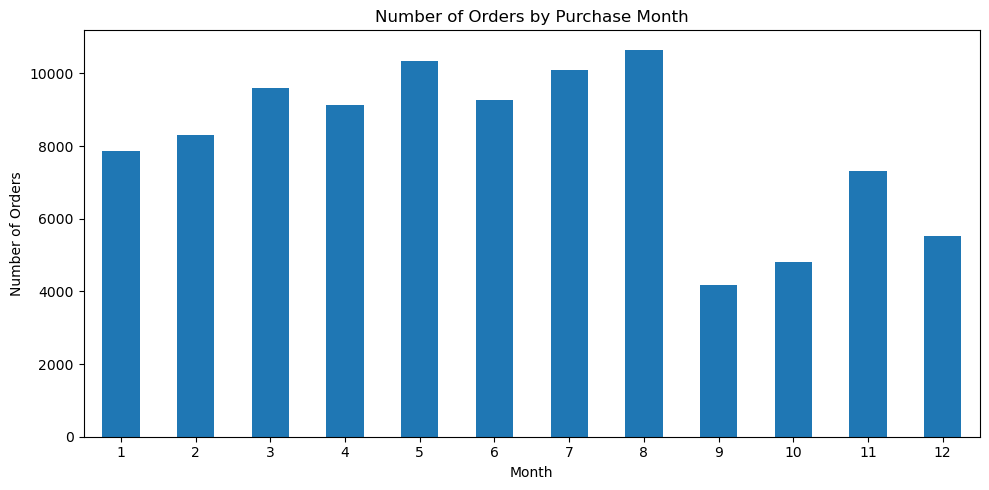

In [122]:
# 3.22 Visualize monthly order activity

import matplotlib.pyplot as plt

monthly_orders = (
    modeling_features["purchase_month"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))
monthly_orders.plot(kind="bar")

plt.title("Number of Orders by Purchase Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chart Interpretation**

The monthly order chart shows variation in purchasing activity throughout the year. August recorded the highest number of orders, while September recorded the lowest. Order volume was relatively high from March to August before dropping in September. These results describe purchasing patterns, but they do not establish which months have higher cancellation risk. I will investigate that relationship during exploratory data analysis.

### 3.23 Visualize Orders by Day of the Week

I will compare order volumes across the seven days of the week to see when customers most frequently place orders. This will help me understand weekly purchasing patterns before examining whether cancellation rates differ by day.

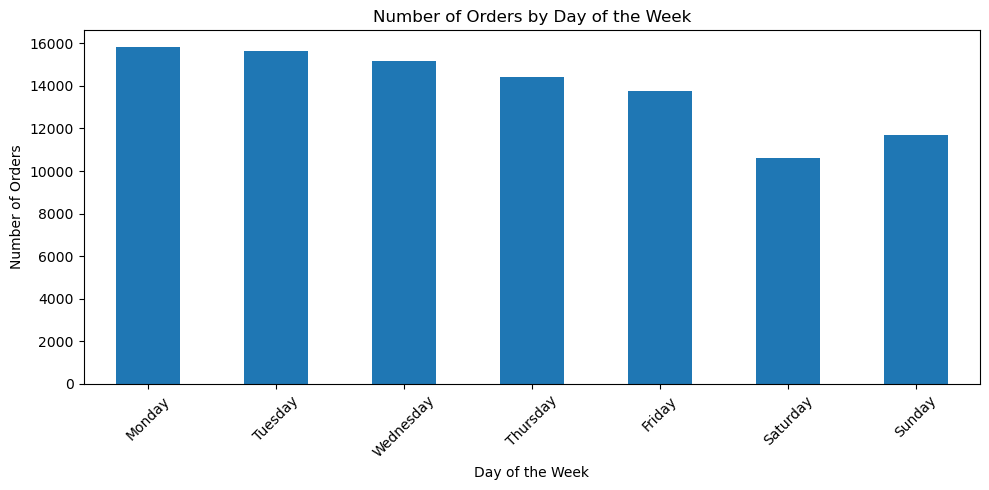

In [123]:
# 3.23 Visualize orders by day of the week

day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

daily_orders = (
    modeling_features["purchase_day_of_week"]
    .value_counts()
    .sort_index()
)

daily_orders.index = daily_orders.index.map(day_names)

plt.figure(figsize=(10, 5))
daily_orders.plot(kind="bar")

plt.title("Number of Orders by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Chart Interpretation**

The chart shows that order activity is highest on Monday and lowest on Saturday. Order volumes generally decrease throughout the working week, followed by a slight increase on Sunday. This suggests that customers' purchasing activity varies by day of the week. I will investigate whether these differences are also associated with cancellation rates during exploratory data analysis.

### 3.24 Visualize Orders by Purchase Hour

I will examine the number of orders placed at each hour of the day to understand daily purchasing patterns. This will help identify the busiest and quietest hours before I investigate whether purchase time is associated with cancellation risk.

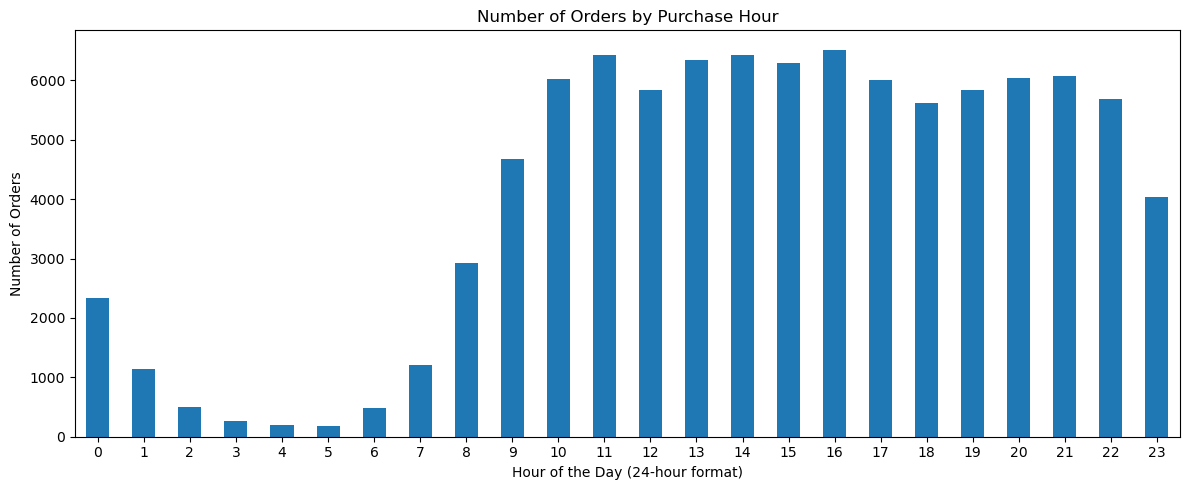

In [124]:
# 3.24 Visualize orders by purchase hour

hourly_orders = (
    modeling_features["purchase_hour"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))
hourly_orders.plot(kind="bar")

plt.title("Number of Orders by Purchase Hour")
plt.xlabel("Hour of the Day (24-hour format)")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chart Interpretation**

The hourly order chart shows that purchasing activity is lowest during the early morning hours and increases as the day progresses. Order volume peaks at 11:00 AM, with activity remaining relatively high throughout the afternoon and evening. The lowest activity occurs at 5:00 AM. These patterns help describe when customers place orders, but further analysis is needed to determine whether purchase hour is associated with cancellation risk.

### 3.25 Data Preparation Summary

During data preparation, I created working copies of the source datasets, converted timestamp columns, examined order statuses, and defined the cancellation target. I summarized payment and order-item information, added product categories, checked dataset coverage, and merged the order-level summaries without losing records or creating duplicate order IDs.

I also investigated missing payment and item records, reviewed potential data leakage, and created initial calendar features from the order purchase timestamp. The initial modeling dataset contains 97,103 orders and has no missing values in its seven columns. The target remains highly imbalanced, with canceled orders accounting for approximately 0.64% of the dataset. I will address this imbalance during modeling and use evaluation metrics suitable for the cancellation class.

# 4. Exploratory Data Analysis (EDA)

In this phase, I will explore the prepared dataset to understand patterns in order cancellations. I will compare canceled and delivered orders, examine cancellation rates across different purchasing periods, and investigate which characteristics may be associated with cancellations.

The analysis will focus on cancellation rates rather than order counts alone, since canceled orders make up only a small proportion of the dataset. These findings will help guide feature selection and modeling, although any relationships identified will be treated as associations rather than proof of causation.

### 4.1 Review the Target Distribution

Before investigating individual features, I will review the balance between canceled and delivered orders. This provides a baseline for interpreting the analysis and reinforces why cancellation-specific metrics will be important when evaluating the model.

In [125]:
# 4.1 Review the target distribution

target_counts = modeling_features["is_canceled"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "Order Status": ["Delivered", "Canceled"],
    "Number of Orders": [
        target_counts.get(0, 0),
        target_counts.get(1, 0)
    ]
})

target_summary["Percentage"] = (
    target_summary["Number of Orders"]
    / len(modeling_features) * 100
).round(2)

display(target_summary)

,Order Status,Number of Orders,Percentage
0,Delivered,96478,99.36
1,Canceled,625,0.64


**Summary**

The target distribution shows that 96,478 orders were delivered, representing 99.36% of the dataset, while 625 orders were canceled, representing 0.64%. This substantial imbalance means that a model could achieve high accuracy simply by predicting that most orders will be delivered. I will therefore focus on cancellation-specific metrics, particularly recall, precision, and F1-score, during model evaluation.

### 4.2 Cancellation Rates by Purchase Month

I will compare cancellation rates across the months of the year to investigate whether cancellation risk varies with the time of purchase. I will calculate the percentage of orders canceled within each month rather than comparing cancellation counts alone, since the total number of orders differs across months.

In [126]:
# 4.2 Calculate cancellation rates by purchase month

monthly_cancellation = (
    modeling_features.groupby("purchase_month")
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
)

monthly_cancellation["cancellation_rate_pct"] = (
    monthly_cancellation["canceled_orders"]
    / monthly_cancellation["total_orders"] * 100
).round(2)

display(monthly_cancellation)

,total_orders,canceled_orders,cancellation_rate_pct
purchase_month,,,
1,7856,37,0.47
2,8298,90,1.08
3,9608,59,0.61
4,9134,33,0.36
5,10348,53,0.51
6,9268,34,0.37
7,10100,69,0.68
8,10655,111,1.04
9,4188,37,0.88


**Summary**

The monthly analysis shows that cancellation rates vary throughout the year. October recorded the highest rate at 1.13%, followed by February at 1.08% and August at 1.04%. December had the lowest rate at 0.20%. August had the largest number of canceled orders, with 111 cancellations. These findings suggest that cancellation patterns may vary by purchase month, although further analysis is needed before drawing conclusions about the reasons for these differences.

### 4.3 Visualize Cancellation Rates by Purchase Month

I will visualize the monthly cancellation rates to make the differences between months easier to compare. This will help highlight periods with relatively higher or lower cancellation rates while keeping the focus on rates rather than total order volume.

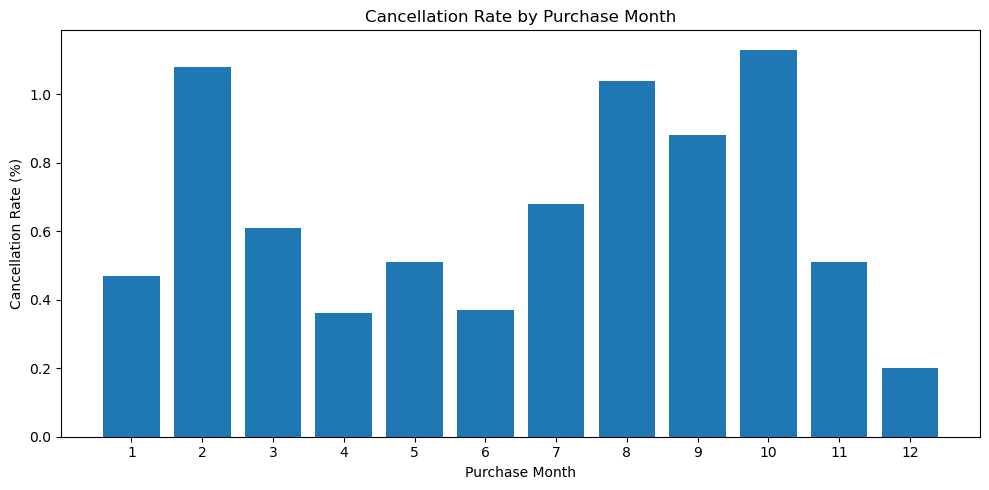

In [127]:
# 4.3 Visualize cancellation rates by purchase month

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_cancellation.index,
    monthly_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate by Purchase Month")
plt.xlabel("Purchase Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

**Chart Interpretation**

The chart highlights differences in cancellation rates across the months. October recorded the highest rate at 1.13%, followed by February at 1.08% and August at 1.04%. December had the lowest rate at 0.20%. These differences suggest that cancellation rates may vary by purchase month, but further analysis is needed to determine whether the pattern is consistent and useful for predicting cancellations.

### 4.4 Cancellation Rates by Day of the Week

I will compare cancellation rates across the days of the week to investigate whether the likelihood of cancellation differs depending on when an order is placed. I will calculate the rate within each day so that differences in order volume do not dominate the comparison.

In [128]:
# 4.4 Calculate cancellation rates by day of the week

day_cancellation = (
    modeling_features.groupby("purchase_day_of_week")
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
)

day_cancellation["cancellation_rate_pct"] = (
    day_cancellation["canceled_orders"]
    / day_cancellation["total_orders"] * 100
).round(2)

day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

day_cancellation.index = day_cancellation.index.map(day_names)
display(day_cancellation)

,total_orders,canceled_orders,cancellation_rate_pct
purchase_day_of_week,,,
Monday,15816,115,0.73
Tuesday,15615,112,0.72
Wednesday,15172,96,0.63
Thursday,14423,100,0.69
Friday,13757,72,0.52
Saturday,10617,62,0.58
Sunday,11703,68,0.58


**Summary**

The analysis shows modest differences in cancellation rates across the days of the week. Monday recorded the highest rate at 0.73%, followed closely by Tuesday at 0.72%. Friday had the lowest rate at 0.52%, while Saturday and Sunday both recorded 0.58%. These results suggest that purchase day may be associated with cancellation patterns, but further analysis is needed to determine whether the differences are meaningful for prediction.

### 4.5 Visualize Cancellation Rates by Day of the Week

I will create a bar chart to compare cancellation rates across the days of the week. This will make it easier to identify differences between weekdays and weekends before examining other purchasing patterns.

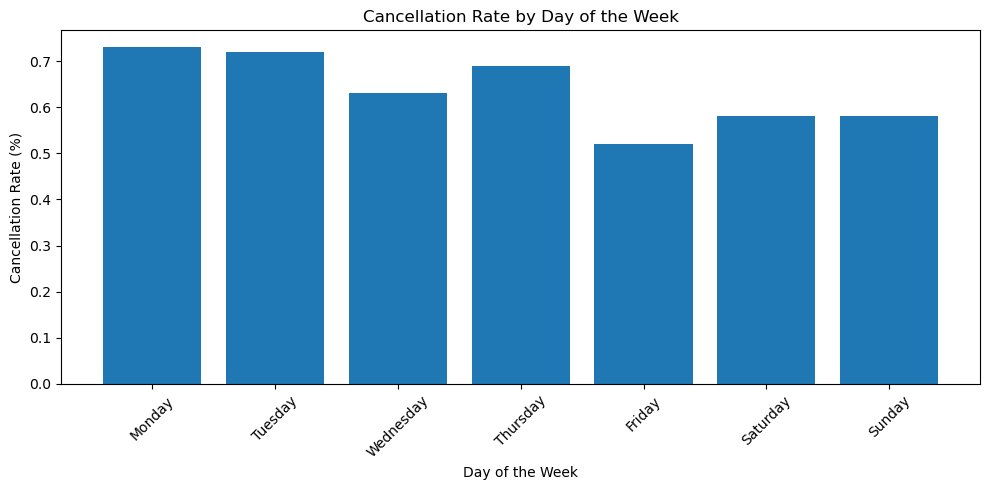

In [129]:
# 4.5 Visualize cancellation rates by day of the week

plt.figure(figsize=(10, 5))

plt.bar(
    day_cancellation.index,
    day_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Chart Interpretation**

The chart shows modest differences in cancellation rates across the week. Monday and Tuesday have the highest rates, while Friday has the lowest. Saturday and Sunday share the same rate of 0.58%. Although purchase day may provide some useful information, these patterns alone do not establish whether it will be a strong predictor of cancellations.

### 4.6 Cancellation Rates by Purchase Hour

I will examine cancellation rates by the hour an order was placed. This will help me see whether cancellations are more common during particular times of the day, rather than relying only on the total number of orders placed at each hour.

In [130]:
# 4.6 Calculate cancellation rates by purchase hour

hourly_cancellation = (
    modeling_features.groupby("purchase_hour")
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
)

hourly_cancellation["cancellation_rate_pct"] = (
    hourly_cancellation["canceled_orders"]
    / hourly_cancellation["total_orders"] * 100
).round(2)

display(hourly_cancellation)

,total_orders,canceled_orders,cancellation_rate_pct
purchase_hour,,,
0,2338,17,0.73
1,1142,9,0.79
2,498,2,0.40
3,261,2,0.77
4,203,0,0.00
5,184,2,1.09
6,485,7,1.44
7,1206,7,0.58
8,2923,16,0.55


**Summary**

Cancellation rates differ across purchase hours. The highest rate was recorded at 6:00 AM (1.44%), while 2:00 AM and 11:00 PM had the lowest rates (0.40%). However, order volumes are much lower during some early-morning hours, so small changes in cancellation counts can noticeably affect the percentages. These patterns are useful for exploration, but further analysis is needed to determine how much purchase hour contributes to predicting cancellations.

### 4.7 Visualize Cancellation Rates by Purchase Hour

I will plot cancellation rates across the 24-hour day to see how the rates change over time. I will use cancellation percentages rather than total cancellations so that hours with different order volumes can be compared more fairly.

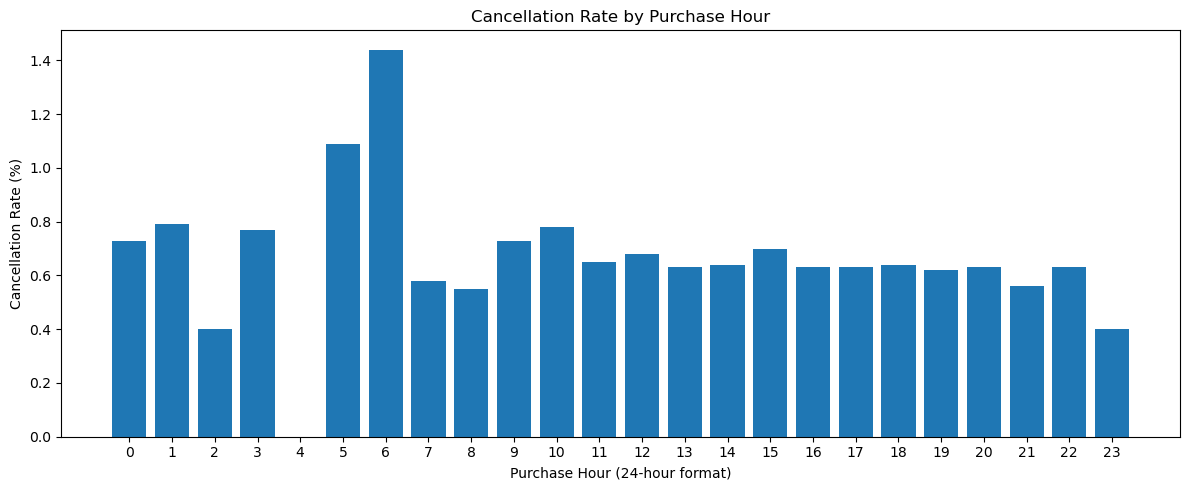

In [131]:
# 4.7 Visualize cancellation rates by purchase hour

plt.figure(figsize=(12, 5))

plt.bar(
    hourly_cancellation.index,
    hourly_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate by Purchase Hour")
plt.xlabel("Purchase Hour (24-hour format)")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

**Chart Interpretation**

The chart shows that cancellation rates vary by purchase hour, with the highest rate occurring at 6:00 AM. Rates are generally more stable during the busier daytime and evening hours. However, fewer orders are placed during the early morning, so the higher rates in that period should be interpreted cautiously. Purchase hour may provide useful information for the cancellation analysis, but its predictive value will be assessed during modeling.

### 4.8 Cancellation Rates: Weekdays vs. Weekends

I will compare cancellation rates for weekday and weekend purchases to see whether the two groups show different patterns. This will provide a simpler comparison than looking at each day individually.

In [132]:
# 4.8 Compare cancellation rates on weekdays and weekends

weekend_cancellation = (
    modeling_features.groupby("is_weekend")
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
)

weekend_cancellation["cancellation_rate_pct"] = (
    weekend_cancellation["canceled_orders"]
    / weekend_cancellation["total_orders"] * 100
).round(2)

weekend_cancellation.index = weekend_cancellation.index.map({
    0: "Weekday",
    1: "Weekend"
})

display(weekend_cancellation)

,total_orders,canceled_orders,cancellation_rate_pct
is_weekend,,,
Weekday,74783,495,0.66
Weekend,22320,130,0.58


**Summary**

Weekday orders had a cancellation rate of 0.66%, compared with 0.58% for weekend orders. Although cancellations were slightly more common on weekdays, the difference was small. This suggests that weekend status may provide some information about cancellation patterns, but its usefulness as a predictor will need to be evaluated during modeling.

### 4.9 Visualize Weekday vs. Weekend Cancellation Rates

I will use a bar chart to compare the cancellation rates for weekday and weekend orders. This will make the difference between the two groups easier to see.

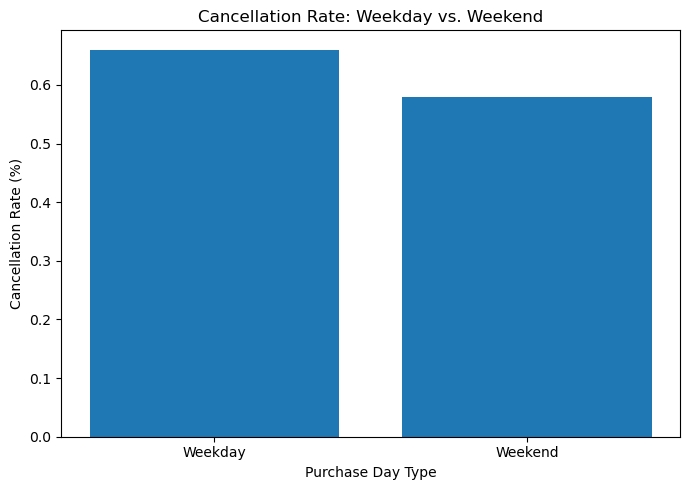

In [133]:
# 4.9 Visualize weekday vs. weekend cancellation rates

plt.figure(figsize=(7, 5))

plt.bar(
    weekend_cancellation.index,
    weekend_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate: Weekday vs. Weekend")
plt.xlabel("Purchase Day Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

**Chart Interpretation**

The chart shows a slightly higher cancellation rate for weekday orders (0.66%) than for weekend orders (0.58%). The difference is small, suggesting that weekend status alone may provide limited information about cancellation risk. I will retain this finding for comparison during the modeling stage.

### 4.10 Summary of Purchase-Time Analysis

The analysis shows that cancellation rates vary across purchase periods, although the differences are generally modest. February, August, and October had relatively high monthly cancellation rates, while December had the lowest. Monday recorded the highest cancellation rate by day of the week, and 6:00 AM had the highest rate by purchase hour. Weekday orders also had a slightly higher cancellation rate than weekend orders.

These results describe patterns in the historical data; they do not establish causation or confirm which features will be useful for prediction. The dataset is highly imbalanced, with canceled orders accounting for only 0.64% of the modeling population. This imbalance will need careful attention during model training and evaluation.

### 4.11 Cancellation Rates by Purchase Year

I will compare cancellation rates across purchase years to see whether the proportion of canceled orders changed over time. Since the number of orders differs considerably between years, I will compare cancellation percentages rather than cancellation counts alone.

In [134]:
# 4.11 Calculate cancellation rates by purchase year

yearly_cancellation = (
    modeling_features.groupby("purchase_year")
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
)

yearly_cancellation["cancellation_rate_pct"] = (
    yearly_cancellation["canceled_orders"]
    / yearly_cancellation["total_orders"] * 100
).round(2)

display(yearly_cancellation)

,total_orders,canceled_orders,cancellation_rate_pct
purchase_year,,,
2016,293,26,8.87
2017,43693,265,0.61
2018,53117,334,0.63


**Summary**

The cancellation rate was 8.87% in 2016, compared with 0.61% in 2017 and 0.63% in 2018. However, only 293 orders were recorded in 2016, far fewer than in the following years. The unusually high rate should therefore be interpreted cautiously. Cancellation rates were relatively similar in 2017 and 2018, suggesting little difference between these two years in the observed data.


### 4.12 Visualize Cancellation Rates by Purchase Year

I will plot cancellation rates by purchase year to make the differences easier to compare. I will also keep the order counts in mind when interpreting the results, especially for 2016, which has a much smaller sample.

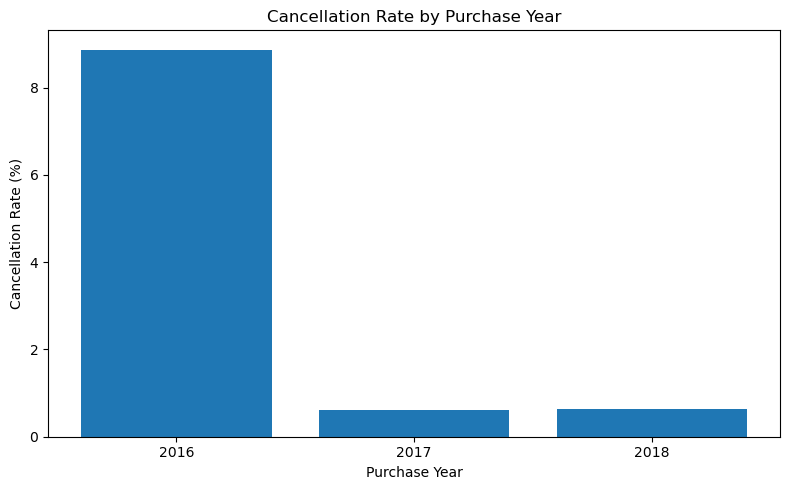

In [135]:
# 4.12 Visualize cancellation rates by purchase year

plt.figure(figsize=(8, 5))

plt.bar(
    yearly_cancellation.index.astype(str),
    yearly_cancellation["cancellation_rate_pct"]
)

plt.title("Cancellation Rate by Purchase Year")
plt.xlabel("Purchase Year")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

The cancellation rate was higher in 2016 than in 2017 and 2018. However, only 293 orders were recorded in 2016, so this rate may be less stable than the rates for later years. Cancellation rates were relatively similar in 2017 and 2018, at 0.61% and 0.63%, respectively. I will keep the difference in sample sizes in mind when interpreting these results.

### 4.13 Cancellation Rates by Payment Type

I will compare cancellation rates across payment types to see whether some methods are associated with higher cancellation rates than others. I will also consider the number of orders in each group, since a higher rate in a small group may be less reliable.

In [136]:
# 4.13 Cancellation rates by payment type

payment_analysis = modeling_orders[
    ["order_id", "is_canceled"]
].merge(
    payment_summary[["order_id", "payment_type"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

payment_type_analysis = payment_analysis.groupby(
    "payment_type",
    dropna=False
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

payment_type_analysis["cancellation_rate_pct"] = (
    payment_type_analysis["canceled_orders"]
    / payment_type_analysis["total_orders"]
    * 100
).round(2)

payment_type_analysis = payment_type_analysis.sort_values(
    "cancellation_rate_pct",
    ascending=False
)

display(payment_type_analysis)

,total_orders,canceled_orders,cancellation_rate_pct
payment_type,,,
not_defined,3,3,100.00
voucher,3065,88,2.87
credit_card,73257,432,0.59
boleto,19286,95,0.49
debit_card,1491,7,0.47
NaN,1,0,0.00


**Interpretation**

Voucher payments had the highest cancellation rate among the main payment types, at 2.87%, compared with 0.59% for credit cards, 0.49% for boleto, and 0.47% for debit cards. However, the `not_defined` category had a 100% cancellation rate based on only three orders, so this result should be interpreted cautiously. The voucher cancellation rate is worth investigating further, although this comparison alone does not establish that the payment method causes cancellations.

### 4.14 Cancellation Rates by Product Category

I will compare cancellation rates across product categories to identify whether some categories have higher cancellation rates than others. I will consider the number of orders in each category when interpreting the results, since rates based on small groups may be less reliable.

In [137]:
# 4.14 Cancellation rates by product category

category_analysis = modeling_dataset[
    ["order_id", "is_canceled"]
].merge(
    order_category_summary[
        ["order_id", "primary_product_category"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

category_analysis["primary_product_category"] = (
    category_analysis["primary_product_category"]
    .fillna("no_item_record")
)

category_rates = category_analysis.groupby(
    "primary_product_category"
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

category_rates["cancellation_rate_pct"] = (
    category_rates["canceled_orders"]
    / category_rates["total_orders"]
    * 100
).round(2)

category_rates = category_rates.sort_values(
    "cancellation_rate_pct",
    ascending=False
)

display(category_rates.head(15))

,total_orders,canceled_orders,cancellation_rate_pct
primary_product_category,,,
no_item_record,164,164,100.00
pc_gamer,7,1,14.29
portateis_cozinha_e_preparadores_de_alimentos,14,1,7.14
diapers_and_hygiene,26,1,3.85
dvds_blu_ray,57,2,3.51
fixed_telephony,215,3,1.40
books_general_interest,502,7,1.39
small_appliances,612,8,1.31
home_appliances_2,229,3,1.31


**Interpretation**

The cancellation rates varied across product categories. PC gaming products had a cancellation rate of 14.29%, but this was based on only seven orders, including one cancellation, so the result should be interpreted cautiously. Other categories, including kitchen appliances and diapers and hygiene products, also showed relatively high rates but had small order counts.

The most notable finding was that all 164 orders without item records were canceled. This suggests that the absence of item records is strongly associated with the canceled order status in this dataset. However, this pattern may reflect how canceled orders are recorded rather than a cause of cancellation. I will keep this data-quality issue in mind when preparing features for modeling.



### 4.15 Cancellation Rates by Order Value

I will examine whether cancellation rates differ across order-value groups. This may help identify whether lower- or higher-value orders show different cancellation patterns. I will also consider missing payment records and ensure that any features used for prediction would be available at the intended prediction time.

In [138]:
# 4.15 Compare order values for canceled and delivered orders

value_analysis = modeling_dataset[
    ["is_canceled", "total_payment_value"]
].copy()

value_analysis["order_outcome"] = value_analysis[
    "is_canceled"
].map({
    0: "Delivered",
    1: "Canceled"
})

display(
    value_analysis.groupby("order_outcome")["total_payment_value"]
    .agg(["count", "median", "mean"])
    .round(2)
)

print("\nMissing payment values by order outcome:")
display(
    value_analysis.groupby("order_outcome")["total_payment_value"]
    .apply(lambda x: x.isna().sum())
    .rename("missing_payment_values")
)

,count,median,mean
order_outcome,,,
Canceled,625,110.32,229.21
Delivered,96477,105.28,159.86



Missing payment values by order outcome:


order_outcome
Canceled     0
Delivered    1
Name: missing_payment_values, dtype: int64

**Interpretation**

Canceled orders had a median payment value of 110.32, compared with 105.28 for delivered orders. The mean payment value was also higher for canceled orders, at 229.21 compared with 159.86 for delivered orders. This suggests that canceled orders tended to have higher payment values, particularly when comparing the averages.

The mean is higher than the median for both groups, indicating that some high-value orders may be influencing the averages. These results show an association between order value and cancellation status, but they do not establish that higher order values cause cancellations. Payment-value features will also need to be assessed carefully before modeling to ensure they would be available at the intended prediction time.

### 4.16 Cancellation Rates by Number of Order Items

I will examine whether cancellation rates vary with the number of items in an order. This may help identify patterns between order size and cancellation status. Orders without recorded item information will be handled separately because missing item records may be associated with canceled orders.

In [139]:
# 4.16 Cancellation rates by number of order items

item_analysis = modeling_dataset[
    ["is_canceled", "total_order_items"]
].copy()

item_analysis["item_count_group"] = (
    item_analysis["total_order_items"]
    .fillna(0)
    .astype(int)
    .astype(str)
)

item_analysis.loc[
    item_analysis["total_order_items"].isna(),
    "item_count_group"
] = "No item record"

item_count_rates = item_analysis.groupby(
    "item_count_group"
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

item_count_rates["cancellation_rate_pct"] = (
    item_count_rates["canceled_orders"]
    / item_count_rates["total_orders"]
    * 100
).round(2)

display(
    item_count_rates.sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
)

,total_orders,canceled_orders,cancellation_rate_pct
item_count_group,,,
No item record,164,164,100.00
5,200,7,3.50
6,194,3,1.55
1,87263,420,0.48
4,497,2,0.40
2,7418,26,0.35
3,1309,3,0.23
10,8,0,0.00
13,1,0,0.00


**Interpretation**

Orders containing five items had a cancellation rate of 3.50%, while orders containing six items had a rate of 1.55%. However, these groups had only 200 and 194 orders, respectively, so the rates should be interpreted cautiously. Orders containing one item accounted for most of the dataset, with 87,263 orders and a cancellation rate of 0.48%.

The most notable result was that all 164 orders without recorded item information were canceled. This reinforces the need to distinguish missing item records from actual item counts. Overall, the results suggest that cancellation rates may vary with order size, but the smaller groups have limited evidence, and the association does not establish causation.

### 4.17 Cancellation Rates by Payment Installments

I will compare cancellation rates across orders with different numbers of payment installments to see whether any patterns emerge. I will consider the number of orders in each group when interpreting the results. Since installment information may not be available at the initial prediction point, I will treat this analysis as exploratory rather than automatically including it in the predictive model.

In [140]:
# 4.17 Cancellation rates by payment installments

installment_analysis = modeling_dataset[
    ["is_canceled", "total_installments"]
].copy()

installment_analysis["installment_group"] = (
    installment_analysis["total_installments"]
    .fillna(0)
    .astype(int)
    .astype(str)
)

installment_analysis.loc[
    installment_analysis["total_installments"].isna(),
    "installment_group"
] = "Missing"

installment_rates = installment_analysis.groupby(
    "installment_group"
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

installment_rates["cancellation_rate_pct"] = (
    installment_rates["canceled_orders"]
    / installment_rates["total_orders"]
    * 100
).round(2)

display(
    installment_rates.sort_values(
        "cancellation_rate_pct",
        ascending=False
    )
)

,total_orders,canceled_orders,cancellation_rate_pct
installment_group,,,
13,29,1,3.45
11,127,2,1.57
9,671,7,1.04
8,4138,30,0.72
10,5081,35,0.69
3,10476,71,0.68
1,45181,309,0.68
4,7056,44,0.62
5,5180,30,0.58


**Interpretation**

Orders with 13 installments had the highest cancellation rate at 3.45%, followed by orders with 11 installments at 1.57%. However, these groups contained only 29 and 127 orders, respectively, so their rates should be interpreted cautiously. Orders with one installment had 45,181 orders and a cancellation rate of 0.68%, while orders with two installments had a rate of 0.50%.

Several installment groups recorded no cancellations, but some contained very few orders. Therefore, a zero cancellation rate does not necessarily indicate lower risk. Overall, the results suggest differences in cancellation rates across installment groups, but they do not establish that the number of installments causes cancellations. Installment information will remain exploratory until its availability at the intended prediction time is confirmed.

### 4.18 Cancellation Rates by Product Price

I will examine whether cancellation rates differ across product-price ranges. This analysis may help identify patterns between the price of individual products and cancellation outcomes. I will account for missing product records and interpret results from smaller groups cautiously.

In [141]:
# 4.18 Cancellation rates by average item price

price_analysis = modeling_dataset[
    ["is_canceled", "average_item_price"]
].copy()

price_analysis["price_group"] = pd.cut(
    price_analysis["average_item_price"],
    bins=[-float("inf"), 50, 100, 200, 500, float("inf")],
    labels=[
        "Up to 50",
        "50–100",
        "100–200",
        "200–500",
        "Above 500"
    ]
)

price_analysis["price_group"] = (
    price_analysis["price_group"]
    .astype("object")
    .fillna("No item record")
)

price_rates = price_analysis.groupby(
    "price_group",
    observed=False
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

price_rates["cancellation_rate_pct"] = (
    price_rates["canceled_orders"]
    / price_rates["total_orders"]
    * 100
).round(2)

display(price_rates)

,total_orders,canceled_orders,cancellation_rate_pct
price_group,,,
100–200,23967,100,0.42
200–500,9286,67,0.72
50–100,28562,124,0.43
Above 500,2995,29,0.97
No item record,164,164,100.00
Up to 50,32129,141,0.44


**Interpretation**

Among orders with recorded item prices, orders with an average item price above 500 had the highest cancellation rate at 0.97%. Orders in the 200–500 range followed at 0.72%, while the remaining price groups had rates between 0.42% and 0.44%. This suggests that orders containing higher-priced items may have somewhat higher cancellation rates in this dataset.

The most notable result was the 100% cancellation rate for orders without item records. Since all 164 orders in this group were canceled, this pattern likely reflects how canceled orders are represented in the dataset rather than a genuine price-related risk. The results show an association, not proof that higher prices cause cancellations. I will also verify whether item-price information would be available at the intended prediction time before considering it for modeling.

### 4.19 Cancellation Rates by Freight Cost

I will examine whether cancellation rates differ across freight-cost ranges. This analysis may help identify patterns between shipping costs and cancellation outcomes. I will handle orders without recorded item information separately and interpret results from smaller groups cautiously.

In [142]:
# 4.19 Cancellation rates by freight-cost range

freight_analysis = modeling_dataset[
    ["is_canceled", "total_freight_value"]
].copy()

freight_analysis["freight_group"] = pd.cut(
    freight_analysis["total_freight_value"],
    bins=[-float("inf"), 20, 50, 100, 200, float("inf")],
    labels=[
        "Up to 20",
        "20–50",
        "50–100",
        "100–200",
        "Above 200"
    ]
)

freight_analysis["freight_group"] = (
    freight_analysis["freight_group"]
    .astype("object")
    .fillna("No item record")
)

freight_rates = freight_analysis.groupby(
    "freight_group",
    observed=False
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

freight_rates["cancellation_rate_pct"] = (
    freight_rates["canceled_orders"]
    / freight_rates["total_orders"]
    * 100
).round(2)

display(freight_rates)


,total_orders,canceled_orders,cancellation_rate_pct
freight_group,,,
100–200,919,8,0.87
20–50,27022,89,0.33
50–100,5044,34,0.67
Above 200,151,1,0.66
No item record,164,164,100.00
Up to 20,63803,329,0.52


**Interpretation**

Among orders with recorded freight costs, the 100–200 range had the highest cancellation rate at 0.87%, followed by the 50–100 range at 0.67%. Orders with freight costs between 20 and 50 had the lowest rate at 0.33%, while orders costing up to 20 had a rate of 0.52%.

The group with freight costs above 200 had a cancellation rate of 0.66%, but it contained only 151 orders and one cancellation, so this result should be interpreted cautiously. As seen in earlier analyses, all 164 orders without item records were canceled. This is likely related to how canceled orders are represented in the dataset and should not be interpreted as evidence that freight costs cause cancellations.

Overall, freight costs show some variation in cancellation rates, but the differences alone do not establish a causal relationship. Freight-cost information will also need to be checked for availability at the intended prediction time before it is considered for modeling.

### 4.20 Cancellation Rates Across Product Categories with Sufficient Orders

To make the product-category analysis more reliable, I will focus on categories with at least 500 orders. This will reduce the influence of very small groups and help me compare cancellation rates across categories with more observations. Orders without recorded item information will remain separate because their cancellation pattern may reflect a data-quality issue.

In [143]:
# 4.20 Cancellation rates for product categories with at least 500 orders

category_analysis = modeling_dataset[
    ["order_id", "is_canceled"]
].merge(
    order_category_summary[
        ["order_id", "primary_product_category"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

category_analysis["primary_product_category"] = (
    category_analysis["primary_product_category"]
    .fillna("no_item_record")
)

category_rates = category_analysis.groupby(
    "primary_product_category"
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

category_rates["cancellation_rate_pct"] = (
    category_rates["canceled_orders"]
    / category_rates["total_orders"]
    * 100
).round(2)

category_rates_filtered = category_rates[
    category_rates["total_orders"] >= 500
].sort_values(
    "cancellation_rate_pct",
    ascending=False
)

display(category_rates_filtered)

,total_orders,canceled_orders,cancellation_rate_pct
primary_product_category,,,
books_general_interest,502,7,1.39
small_appliances,612,8,1.31
musical_instruments,614,8,1.30
unknown,1350,14,1.04
toys,3790,31,0.82
consoles_games,1024,8,0.78
housewares,5707,37,0.65
auto,3828,24,0.63
sports_leisure,7525,47,0.62


**Interpretation**

Among product categories with at least 500 orders, books general interest had the highest cancellation rate at 1.39%, followed by small appliances at 1.31% and musical instruments at 1.30%. In comparison, office furniture had the lowest rate at 0.08%, followed by bed, bath and table products at 0.19%.

These results suggest that cancellation rates vary across product categories. However, the differences should be interpreted in the context of the number of cancellations in each category. For example, books general interest had seven cancellations out of 502 orders, while office furniture had one cancellation out of 1,245 orders. The results show associations rather than evidence that product category causes cancellations. Product-category information must also be assessed for availability at the intended prediction time before being considered for modeling.

### 4.21 Cancellation Rates by Payment Type with Sufficient Orders

I will compare cancellation rates across payment types with at least 500 orders. This will help me focus on payment methods with enough observations for a more meaningful comparison and avoid drawing strong conclusions from categories with very few orders.

In [144]:
# 4.21 Cancellation rates by payment type with at least 500 orders

payment_analysis = modeling_orders[
    ["order_id", "is_canceled"]
].merge(
    payment_summary[["order_id", "payment_type"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

payment_analysis["payment_type"] = (
    payment_analysis["payment_type"]
    .fillna("missing_payment_record")
)

payment_rates = payment_analysis.groupby(
    "payment_type"
).agg(
    total_orders=("is_canceled", "size"),
    canceled_orders=("is_canceled", "sum")
)

payment_rates["cancellation_rate_pct"] = (
    payment_rates["canceled_orders"]
    / payment_rates["total_orders"]
    * 100
).round(2)

payment_rates_filtered = payment_rates[
    payment_rates["total_orders"] >= 500
].sort_values(
    "cancellation_rate_pct",
    ascending=False
)

display(payment_rates_filtered)

,total_orders,canceled_orders,cancellation_rate_pct
payment_type,,,
voucher,3065,88,2.87
credit_card,73257,432,0.59
boleto,19286,95,0.49
debit_card,1491,7,0.47


**Interpretation**

Voucher payments had the highest cancellation rate at 2.87%, with 88 cancellations out of 3,065 orders. Credit card payments had a cancellation rate of 0.59%, followed by boleto at 0.49% and debit card at 0.47%.

The difference suggests that cancellation patterns vary across payment types, particularly for voucher payments. However, these results do not establish that payment method causes cancellations. Other factors may contribute to the observed differences, and payment information must be assessed for availability at the intended prediction time before being considered for the predictive model.

### 4.22 Cancellation Rates by Purchase Month and Year

I will compare cancellation rates across purchase months and years to determine whether monthly patterns remain consistent over time. Since 2016 has fewer orders than 2017 and 2018, I will interpret its cancellation rates cautiously.

In [145]:
# 4.22 Cancellation Rates by Purchase Month and Year

month_year_analysis = modeling_dataset[
    ["order_purchase_timestamp", "is_canceled"]
].copy()

month_year_analysis["purchase_year"] = (
    month_year_analysis["order_purchase_timestamp"].dt.year
)

month_year_analysis["purchase_month"] = (
    month_year_analysis["order_purchase_timestamp"].dt.month
)

month_year_rates = (
    month_year_analysis
    .groupby(["purchase_year", "purchase_month"])
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
    .reset_index()
)

month_year_rates["cancellation_rate_pct"] = (
    month_year_rates["canceled_orders"]
    / month_year_rates["total_orders"] * 100
).round(2)

display(month_year_rates)

,purchase_year,purchase_month,total_orders,canceled_orders,cancellation_rate_pct
0,2016,9,3,2,66.67
1,2016,10,289,24,8.30
2,2016,12,1,0,0.00
3,2017,1,753,3,0.40
4,2017,2,1670,17,1.02
5,2017,3,2579,33,1.28
6,2017,4,2321,18,0.78
7,2017,5,3575,29,0.81
8,2017,6,3151,16,0.51
9,2017,7,3900,28,0.72


**Interpretation:**

The monthly cancellation rates varied across years. In 2017, March had the highest cancellation rate among the months shown with substantial order volumes, at 1.28%. In 2018, August recorded 1.31%, followed by February at 1.10%.

September and October 2018 each recorded a 100% cancellation rate, but these figures were based on only 15 and 4 orders, respectively. Similarly, the high cancellation rate in September 2016 was based on just 3 orders. These small samples make the rates unreliable for drawing broad conclusions.

Overall, the results suggest that monthly cancellation patterns changed across years. However, differences in order volumes and the limited data available for some months should be considered when interpreting the findings.

### 4.23 Visualize Monthly Cancellation Rates by Year

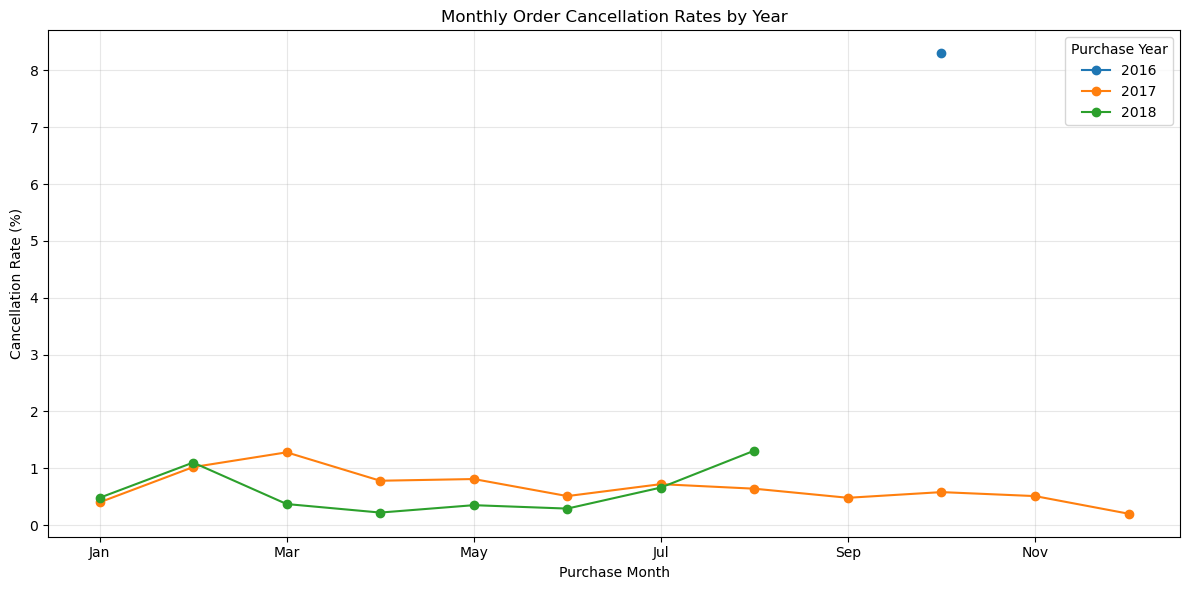

In [146]:
# 4.23 Visualize Monthly Cancellation Rates by Year
# Display only year-month groups with at least 100 orders

import matplotlib.pyplot as plt
import calendar

monthly_chart_data = month_year_rates[
    month_year_rates["total_orders"] >= 100
].copy()

monthly_rate_pivot = monthly_chart_data.pivot(
    index="purchase_month",
    columns="purchase_year",
    values="cancellation_rate_pct"
)

monthly_rate_pivot.index = [
    calendar.month_abbr[month]
    for month in monthly_rate_pivot.index
]

monthly_rate_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Monthly Order Cancellation Rates by Year")
plt.xlabel("Purchase Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)
plt.legend(title="Purchase Year")
plt.tight_layout()
plt.show()

**Interpretation:**

The chart shows that monthly cancellation rates varied across 2017 and 2018. In 2017, March recorded the highest rate at 1.28%, while December had the lowest at 0.20%. In 2018, August had the highest rate among the displayed months at 1.31%, followed by February at 1.10%.

The monthly patterns were not consistent across the two years. For example, March had a higher cancellation rate in 2017 than in 2018, while August had a higher rate in 2018 than in 2017. This suggests that cancellation rates may be influenced by factors beyond a recurring monthly pattern.

The chart excludes year-month groups with fewer than 100 orders for readability. These groups remain in the dataset and are not removed from the overall analysis.

### 4.24 Cancellation Rates by Purchase Day of the Week and Year

I will compare cancellation rates by day of the week across purchase years to determine whether certain days consistently experience higher cancellation rates. This comparison may help identify patterns that are not visible when all years are combined.

In [147]:
# 4.24 Cancellation Rates by Purchase Day of the Week and Year

import calendar
import matplotlib.pyplot as plt

day_year_analysis = modeling_dataset[
    ["order_purchase_timestamp", "is_canceled"]
].copy()

day_year_analysis["purchase_year"] = (
    day_year_analysis["order_purchase_timestamp"].dt.year
)

day_year_analysis["purchase_day"] = (
    day_year_analysis["order_purchase_timestamp"].dt.dayofweek
)

day_year_rates = (
    day_year_analysis
    .groupby(["purchase_year", "purchase_day"])
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
    .reset_index()
)

day_year_rates["cancellation_rate_pct"] = (
    day_year_rates["canceled_orders"]
    / day_year_rates["total_orders"] * 100
).round(2)

day_year_rates["day_name"] = day_year_rates["purchase_day"].map(
    lambda day: calendar.day_name[day]
)

display(day_year_rates)

,purchase_year,purchase_day,total_orders,canceled_orders,cancellation_rate_pct,day_name
0,2016,0,45,4,8.89,Monday
1,2016,1,60,6,10.00,Tuesday
2,2016,2,37,2,5.41,Wednesday
3,2016,3,45,3,6.67,Thursday
4,2016,4,41,2,4.88,Friday
5,2016,5,40,4,10.00,Saturday
6,2016,6,25,5,20.00,Sunday
7,2017,0,6951,47,0.68,Monday
8,2017,1,6958,38,0.55,Tuesday
9,2017,2,6554,46,0.70,Wednesday


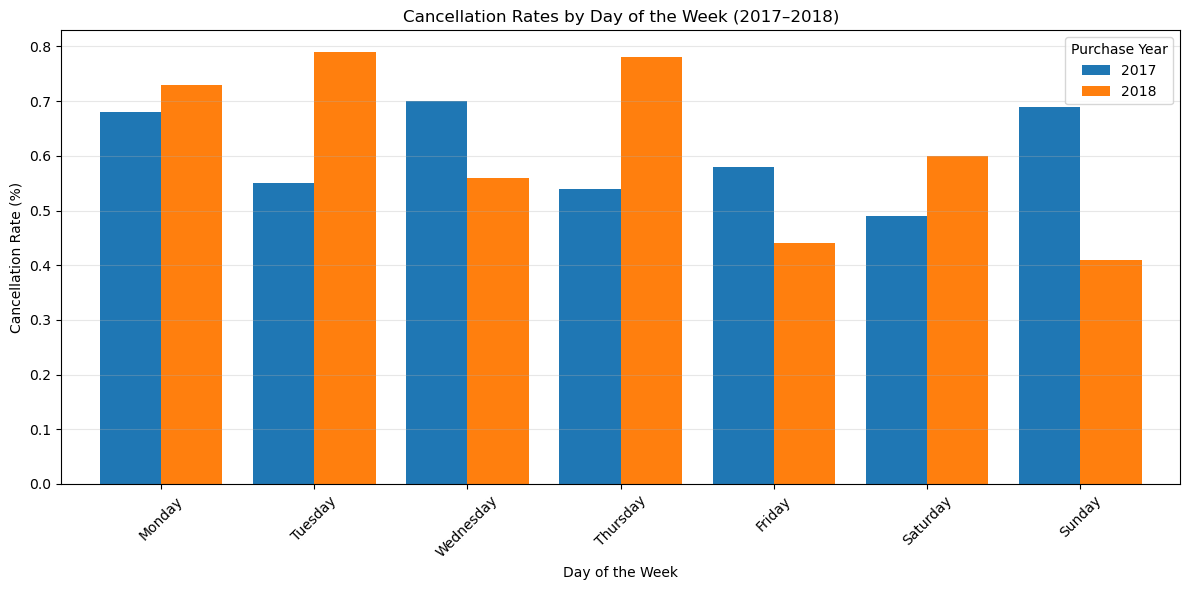

In [148]:
# 4.24 Cancellation Rates by Day of the Week and Year
# Focus on 2017 and 2018 for a clearer comparison

day_rate_pivot = day_year_rates.pivot(
    index="day_name",
    columns="purchase_year",
    values="cancellation_rate_pct"
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_rate_pivot = day_rate_pivot.reindex(day_order)
day_rate_pivot = day_rate_pivot[[2017, 2018]]

day_rate_pivot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Cancellation Rates by Day of the Week (2017–2018)")
plt.xlabel("Day of the Week")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Purchase Year")
plt.tight_layout()
plt.show()

**Interpretation:**

In 2017, Wednesday recorded the highest cancellation rate at 0.70%, while Saturday had the lowest at 0.49%. In 2018, Tuesday had the highest rate at 0.79%, closely followed by Thursday at 0.78%. Sunday recorded the lowest rate in 2018 at 0.41%.

The comparison shows that cancellation patterns by day of the week changed between 2017 and 2018. Tuesday and Thursday had higher rates in 2018, whereas Wednesday, Friday, and Sunday had lower rates. These differences may be worth investigating, but they do not establish the causes of cancellations.

The comparison focuses on 2017 and 2018 because these years contain substantially more orders than 2016. The findings describe observed patterns and should not be interpreted as evidence that a particular day causes cancellations.

### 4.25 Cancellation Rates by Purchase Hour and Year

I will compare cancellation rates by purchase hour across 2017 and 2018 to see whether hourly patterns were consistent between the two years. This analysis may help identify periods worth investigating further, while accounting for differences in order volumes.

In [149]:
# 4.25 Cancellation Rates by Purchase Hour and Year

hour_year_analysis = modeling_dataset[
    ["order_purchase_timestamp", "is_canceled"]
].copy()

hour_year_analysis["purchase_year"] = (
    hour_year_analysis["order_purchase_timestamp"].dt.year
)

hour_year_analysis["purchase_hour"] = (
    hour_year_analysis["order_purchase_timestamp"].dt.hour
)

hour_year_rates = (
    hour_year_analysis
    .groupby(["purchase_year", "purchase_hour"])
    .agg(
        total_orders=("is_canceled", "size"),
        canceled_orders=("is_canceled", "sum")
    )
    .reset_index()
)

hour_year_rates["cancellation_rate_pct"] = (
    hour_year_rates["canceled_orders"]
    / hour_year_rates["total_orders"] * 100
).round(2)

display(hour_year_rates)

,purchase_year,purchase_hour,total_orders,canceled_orders,cancellation_rate_pct
0,2016,0,6,2,33.33
1,2016,1,1,0,0.00
2,2016,2,4,0,0.00
3,2016,4,3,0,0.00
4,2016,7,6,1,16.67
...,...,...,...,...,...
64,2018,19,3183,14,0.44
65,2018,20,3334,19,0.57
66,2018,21,3280,12,0.37
67,2018,22,3032,20,0.66


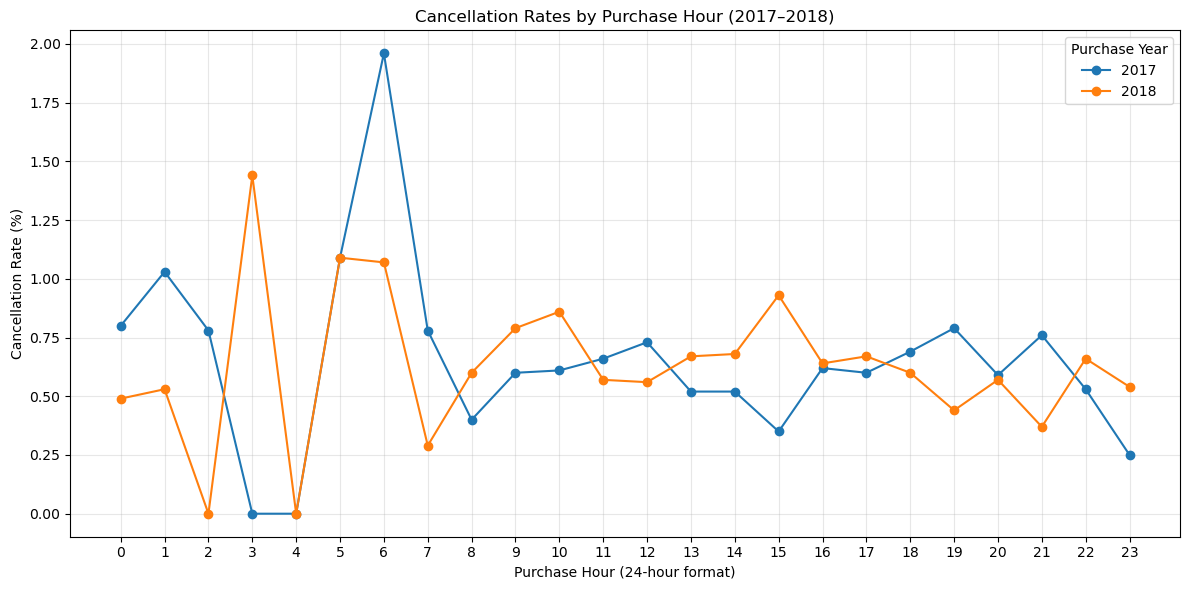

In [150]:
# 4.25 Visualize Cancellation Rates by Purchase Hour and Year

hour_rate_pivot = hour_year_rates.pivot(
    index="purchase_hour",
    columns="purchase_year",
    values="cancellation_rate_pct"
)

# Focus on 2017 and 2018 because 2016 has few orders
hour_rate_pivot = hour_rate_pivot[[2017, 2018]]

hour_rate_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Cancellation Rates by Purchase Hour (2017–2018)")
plt.xlabel("Purchase Hour (24-hour format)")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend(title="Purchase Year")
plt.tight_layout()
plt.show()

**Interpretation:**

The hourly cancellation patterns differed between 2017 and 2018. In 2017, the highest displayed cancellation rate was around 6:00 AM, at approximately 1.96%. In 2018, the highest rate was around 3:00 AM, at approximately 1.45%. These peaks should be interpreted cautiously because the number of orders placed during those hours may be relatively small.

For much of the day, cancellation rates in both years remained below 1%. The chart also shows that the hourly patterns were not identical across the two years. This suggests that purchase hour alone may not provide a consistent explanation for cancellations.

These findings describe associations rather than causes. Before using purchase hour in a predictive model, I will evaluate its usefulness alongside other features and assess model performance on unseen data.

### 4.26 Exploratory Data Analysis Summary

The exploratory analysis revealed several patterns in order cancellations:

- **Target imbalance:** Canceled orders represented approximately 0.64% of the delivered and canceled orders used in this analysis. This imbalance will need to be considered during model training and evaluation.
- **Purchase timing:** Cancellation rates varied by month, day of the week, and purchase hour. Some differences appeared across years, but the patterns were not always consistent.
- **Payment type:** Voucher payments had a higher observed cancellation rate than the other major payment types examined. This is an association and does not establish causation.
- **Order value and item characteristics:** Cancellation rates differed across payment values, item counts, price ranges, freight costs, and product categories. Small groups and missing item records require careful interpretation.
- **Data quality:** All 164 orders without item records in the modeling dataset were canceled. This pattern may reflect a data limitation or a characteristic of canceled orders, so missing item information must not be treated as a reliable predictive signal without further investigation.
- **Yearly comparisons:** The 2016 data contained far fewer orders than the later years, making its cancellation rates less stable.

Overall, the analysis identifies potential relationships worth investigating, but the findings do not prove that any individual factor causes cancellations. The next phase will focus on building and evaluating a predictive model while avoiding data leakage and accounting for the highly imbalanced target.

## Phase 5: Modeling

### 5.1 Define the Initial Modeling Features

I will begin with features derived from the order purchase timestamp because these are available at the time an order is placed. The target variable is `is_canceled`, where 1 represents a canceled order and 0 represents a delivered order.

The dataset contains a highly imbalanced target, with canceled orders representing approximately 0.64% of the selected records. I will account for this imbalance when splitting the data, training models, and evaluating performance. Accuracy alone will not be used to judge model quality.

In [151]:
# 5.1 Define and validate the initial modeling features

feature_columns = [
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "is_weekend"
]

X = modeling_features[feature_columns].copy()
y = modeling_features["is_canceled"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Feature matrix shape: (97103, 5)
Target shape: (97103,)

Missing values in features:
purchase_year           0
purchase_month          0
purchase_day_of_week    0
purchase_hour           0
is_weekend              0
dtype: int64

Target distribution:
is_canceled
0    96478
1      625
Name: count, dtype: int64

Target distribution (%):
is_canceled
0    99.36
1     0.64
Name: proportion, dtype: float64


### 5.2 Split the Data into Training and Testing Sets

I will split the data into training and testing sets using an 80:20 ratio. Stratified sampling will preserve the proportion of canceled and delivered orders in both sets, ensuring that the test set contains enough canceled cases for evaluation.

The test set will remain separate from model training and any resampling or feature-selection decisions.

In [152]:
# 5.2 Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training feature shape: (77682, 5)
Testing feature shape: (19421, 5)

Training target distribution:
is_canceled
0    77182
1      500
Name: count, dtype: int64
is_canceled
0    99.36
1     0.64
Name: proportion, dtype: float64

Testing target distribution:
is_canceled
0    19296
1      125
Name: count, dtype: int64
is_canceled
0    99.36
1     0.64
Name: proportion, dtype: float64


### 5.3 Train a Baseline Logistic Regression Model

I will train a Logistic Regression model using class weights to address the imbalance between canceled and delivered orders. This will serve as the baseline for evaluating whether purchase-time features can identify canceled orders.

I will assess the model using precision, recall, F1-score, a confusion matrix, and average precision rather than relying on accuracy alone.

In [153]:
# 5.3 Train the baseline Logistic Regression model

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


### 5.4 Evaluate the Baseline Logistic Regression Model

I will evaluate the baseline model on the test set, which was not used during training. I will examine precision, recall, F1-score, average precision, and the confusion matrix to understand how well the model identifies canceled orders.

Because cancellations are rare, I will pay particular attention to the model's performance on the canceled class rather than relying on accuracy alone.

Classification Report:
              precision    recall  f1-score   support

   Delivered       0.99      0.54      0.70     19296
    Canceled       0.01      0.47      0.01       125

    accuracy                           0.54     19421
   macro avg       0.50      0.51      0.36     19421
weighted avg       0.99      0.54      0.70     19421

Average Precision (PR-AUC): 0.0087


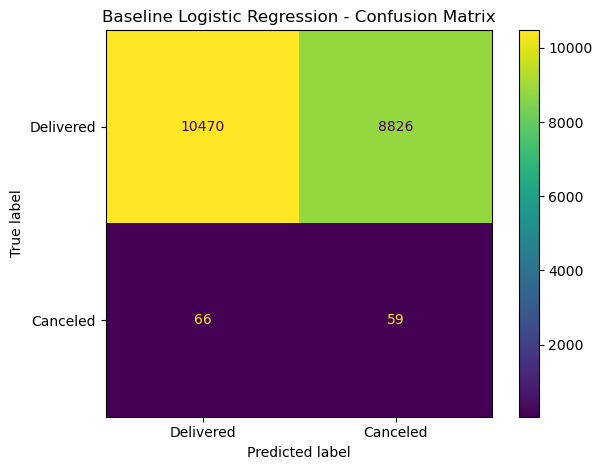

In [154]:
# 5.4 Evaluate the baseline Logistic Regression model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred_baseline = baseline_model.predict(X_test)
y_prob_baseline = baseline_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

print("Average Precision (PR-AUC):",
      round(average_precision_score(y_test, y_prob_baseline), 4))

cm = confusion_matrix(y_test, y_pred_baseline)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Delivered", "Canceled"]
).plot(values_format="d")

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

### 5.5 Train a Decision Tree Classifier

I will train a Decision Tree classifier using the same training data and purchase-time features. I will apply class weighting to account for the imbalance between canceled and delivered orders and compare its performance with the Logistic Regression baseline.

In [155]:
# 5.5 Train a Decision Tree classifier

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


### 5.6 Evaluate the Decision Tree Classifier

I will evaluate the Decision Tree using the same test set and performance metrics as Logistic Regression. This will help me determine whether the model identifies canceled orders more effectively.

Decision Tree Classification Report:
              precision    recall  f1-score   support

   Delivered       1.00      0.69      0.82     19296
    Canceled       0.01      0.60      0.02       125

    accuracy                           0.69     19421
   macro avg       0.50      0.65      0.42     19421
weighted avg       0.99      0.69      0.81     19421

Decision Tree Average Precision (PR-AUC): 0.018


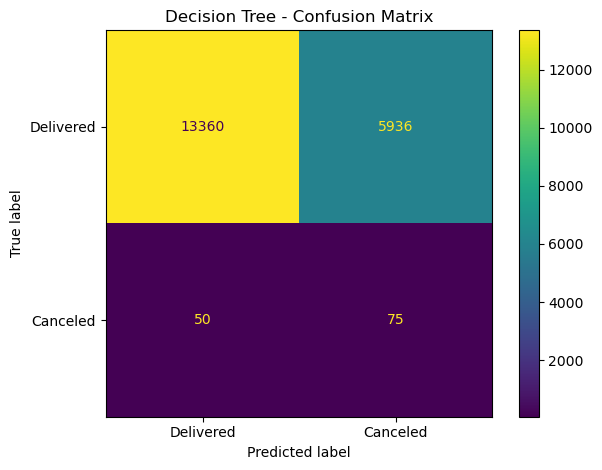

In [156]:
# 5.6 Evaluate the Decision Tree classifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions
y_pred_tree = decision_tree_model.predict(X_test)
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

# Classification report
print("Decision Tree Classification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

# Average Precision (PR-AUC)
print(
    "Decision Tree Average Precision (PR-AUC):",
    round(average_precision_score(y_test, y_prob_tree), 4)
)

# Confusion matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["Delivered", "Canceled"]
).plot(values_format="d")

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation:**

The Decision Tree achieved a recall of 0.60 for canceled orders, improving on the Logistic Regression baseline's recall of 0.47. Its Average Precision score also increased from 0.0087 to 0.018, suggesting a modest improvement in ranking canceled orders above delivered orders.

However, precision remained at 0.01, meaning that most orders predicted as canceled were actually delivered. The results suggest that the Decision Tree performs better than the baseline, but the current purchase-time features still provide limited predictive power.

I will evaluate additional tree-based models before drawing a final conclusion about which model performs best.

### 5.7 Train a Random Forest Classifier

I will train a Random Forest classifier to determine whether combining multiple decision trees improves cancellation prediction. I will use class weighting and evaluate it using the same test set and performance metrics as the previous models.

In [157]:
# 5.7 Train a Random Forest classifier

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 5.8 Evaluate the Random Forest Classifier

I will evaluate the Random Forest using the same test set and metrics as the previous models. This will help me determine whether combining multiple decision trees improves the identification of canceled orders.

Random Forest Classification Report:
              precision    recall  f1-score   support

   Delivered       1.00      0.72      0.83     19296
    Canceled       0.01      0.45      0.02       125

    accuracy                           0.71     19421
   macro avg       0.50      0.58      0.43     19421
weighted avg       0.99      0.71      0.83     19421

Random Forest Average Precision (PR-AUC): 0.0157


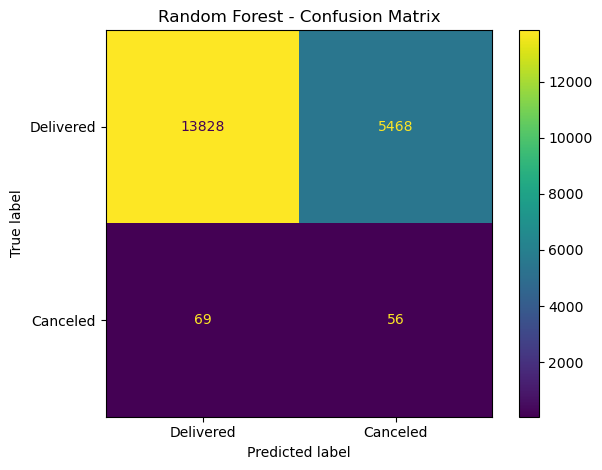

In [158]:
# 5.8 Evaluate the Random Forest classifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Classification report
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

# Average Precision (PR-AUC)
print(
    "Random Forest Average Precision (PR-AUC):",
    round(average_precision_score(y_test, y_prob_rf), 4)
)

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Delivered", "Canceled"]
).plot(values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation:**

The Random Forest achieved a recall of 0.45 for canceled orders, identifying approximately 45% of actual cancellations. This was lower than the recall achieved by both Logistic Regression and the Decision Tree.

Its Average Precision score was 0.0157, which was better than Logistic Regression but lower than the Decision Tree's score of 0.018. Despite its 71% accuracy, the model's low precision indicates that it generates many false cancellation alerts.

Based on the current results, the Decision Tree performs best in terms of cancellation recall and Average Precision. I will evaluate one more model before making a final comparison.

### 5.9 Train a Gradient Boosting Classifier

I will train a Gradient Boosting classifier to compare its ability to identify canceled orders against the three previous models. I will use the same training data and evaluate it with the same metrics to maintain a fair comparison.

In [159]:
# 5.9 Train a Gradient Boosting classifier

from sklearn.ensemble import HistGradientBoostingClassifier

gradient_boosting_model = HistGradientBoostingClassifier(
    max_iter=150,
    max_leaf_nodes=15,
    learning_rate=0.1,
    class_weight="balanced",
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


### 5.10 Evaluate the Gradient Boosting Classifier

I will evaluate the Gradient Boosting model using the same test set as the previous models. I will focus on cancellation precision, recall, F1-score, and Average Precision to assess its performance on the imbalanced dataset.

Gradient Boosting Classification Report:
              precision    recall  f1-score   support

   Delivered       1.00      0.69      0.82     19296
    Canceled       0.01      0.47      0.02       125

    accuracy                           0.69     19421
   macro avg       0.50      0.58      0.42     19421
weighted avg       0.99      0.69      0.81     19421

Gradient Boosting Average Precision (PR-AUC): 0.0155


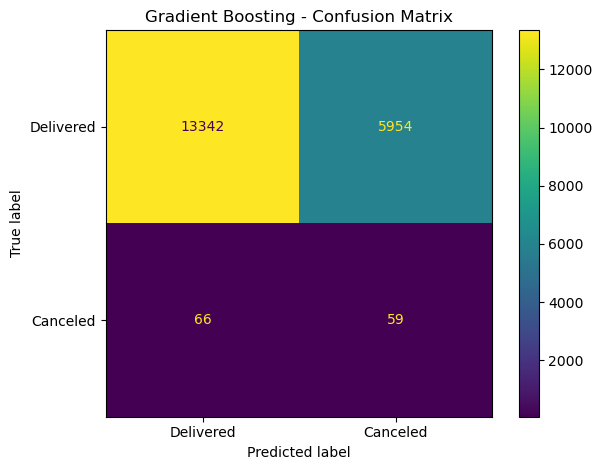

In [160]:
# 5.10 Evaluate the Gradient Boosting classifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions
y_pred_gb = gradient_boosting_model.predict(X_test)
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

# Classification report
print("Gradient Boosting Classification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

# Average Precision (PR-AUC)
print(
    "Gradient Boosting Average Precision (PR-AUC):",
    round(average_precision_score(y_test, y_prob_gb), 4)
)

# Confusion matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)

ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=["Delivered", "Canceled"]
).plot(values_format="d")

plt.title("Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation:**

The Gradient Boosting model achieved a recall of 0.47 for canceled orders, matching the Logistic Regression baseline. Its Average Precision score was 0.0155, which was higher than Logistic Regression's 0.0087 but lower than the Decision Tree's 0.018.

The model's precision of 0.01 indicates that most predicted cancellations were false alarms. Overall, Gradient Boosting did not outperform the Decision Tree on the key cancellation-prediction metrics. I will now compare all four models to identify the strongest candidate for further improvement.

In [161]:
# 5.11 Compare the performance of all four models

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

models = {
    "Logistic Regression": (y_pred_baseline, y_prob_baseline),
    "Decision Tree": (y_pred_tree, y_prob_tree),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "Gradient Boosting": (y_pred_gb, y_prob_gb)
}

comparison_results = []

for model_name, (y_pred, y_prob) in models.items():
    comparison_results.append({
        "Model": model_name,
        "Canceled Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Canceled Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Canceled F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_test, y_prob
        )
    })

model_comparison = pd.DataFrame(comparison_results)

model_comparison = model_comparison.sort_values(
    by="Average Precision", ascending=False
).reset_index(drop=True)

print("Model Performance Comparison:")
display(model_comparison.round(4))

Model Performance Comparison:


,Model,Canceled Precision,Canceled Recall,Canceled F1-Score,Average Precision
0,Decision Tree,0.0125,0.600,0.0244,0.0180
1,Random Forest,0.0101,0.448,0.0198,0.0157
2,Gradient Boosting,0.0098,0.472,0.0192,0.0155
3,Logistic Regression,0.0066,0.472,0.0131,0.0087


### Model Comparison Interpretation

The Decision Tree achieved an Average Precision (PR-AUC) score of 0.0180 and a cancellation recall of 0.60 in the initial experiment. It correctly identified 60% of the canceled orders in the test set.

However, cancellation precision was approximately 0.01, meaning that only a small proportion of orders predicted as canceled were actually canceled. This indicates a high number of false alarms.

Although the Decision Tree performed well relative to the other models in the initial comparison, its performance must also be assessed for overfitting and generalization before selecting a final model. The results from this initial experiment will be compared with those from the expanded feature experiment.

In [162]:
# 5.12 Overfitting and underfitting assessment

from sklearn.metrics import (
    average_precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models_to_check = {
    "Logistic Regression": baseline_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

fit_results = []

for name, model in models_to_check.items():
    train_pred = model.predict(X_train)
    train_prob = model.predict_proba(X_train)[:, 1]

    test_pred = model.predict(X_test)
    test_prob = model.predict_proba(X_test)[:, 1]

    train_ap = average_precision_score(y_train, train_prob)
    test_ap = average_precision_score(y_test, test_prob)

    fit_results.append({
        "Model": name,
        "Train Average Precision": train_ap,
        "Test Average Precision": test_ap,
        "AP Train-Test Gap": train_ap - test_ap,
        "Train Canceled Recall": recall_score(
            y_train, train_pred, zero_division=0
        ),
        "Test Canceled Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "Train Canceled F1": f1_score(
            y_train, train_pred, zero_division=0
        ),
        "Test Canceled F1": f1_score(
            y_test, test_pred, zero_division=0
        )
    })

fit_comparison = pd.DataFrame(fit_results)

display(fit_comparison.round(4))

,Model,Train Average Precision,Test Average Precision,AP Train-Test Gap,Train Canceled Recall,Test Canceled Recall,Train Canceled F1,Test Canceled F1
0,Logistic Regression,0.0098,0.0087,0.0012,0.516,0.472,0.0143,0.0131
1,Decision Tree,0.0183,0.0180,0.0003,0.532,0.600,0.0218,0.0244
2,Random Forest,0.0326,0.0157,0.0169,0.720,0.448,0.0320,0.0198
3,Gradient Boosting,0.0211,0.0155,0.0055,0.606,0.472,0.0248,0.0192


### Overfitting and Underfitting Interpretation

The training and test results help assess how well each model generalizes to unseen data.

- **Logistic Regression:** The small Average Precision gap of 0.0012 suggests consistent performance between training and test data, although its overall predictive performance is weak.
- **Decision Tree:** The very small gap of 0.0003 suggests stable performance across the two datasets. It achieved the highest test Average Precision (0.0180) and cancellation recall (0.60) in the initial experiment.
- **Random Forest:** The larger gap of 0.0169 suggests possible overfitting. Its training Average Precision was 0.0326, compared with 0.0157 on the test set. Cancellation recall also fell from 0.720 to 0.448.
- **Gradient Boosting:** The gap of 0.0055 suggests some difference between training and test performance, although the evidence of overfitting is less pronounced than for Random Forest.

Overall, the Decision Tree performed most consistently while achieving the strongest test Average Precision in this initial experiment. However, all four models have weak cancellation precision, so many predicted cancellations may be false alarms. These results should be considered alongside the later expanded-feature experiment before choosing the final model.

A small train-test gap alone does not prove that a model is well-fitted; it must also be considered alongside its predictive performance.

### Improve the features before final model selection

In [163]:
# Inspect available columns for feature engineering

print("Available columns in modeling_dataset:")
for column in modeling_dataset.columns:
    print(column)

Available columns in modeling_dataset:
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
is_canceled
total_payment_value
payment_record_count
total_installments
payment_type
total_order_items
total_item_price
total_freight_value
average_item_price
distinct_product_categories
total_distinct_products
primary_product_category


In [164]:
# Inspect missing values in potential predictor features

candidate_features = [
    "total_payment_value",
    "payment_record_count",
    "total_installments",
    "payment_type",
    "total_order_items",
    "total_item_price",
    "total_freight_value",
    "average_item_price",
    "distinct_product_categories",
    "total_distinct_products",
    "primary_product_category"
]

missing_summary = pd.DataFrame({
    "Missing Count": modeling_dataset[candidate_features].isna().sum(),
    "Missing Percentage": (
        modeling_dataset[candidate_features].isna().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
total_freight_value,164,0.17
total_item_price,164,0.17
total_order_items,164,0.17
total_distinct_products,164,0.17
distinct_product_categories,164,0.17
primary_product_category,164,0.17
average_item_price,164,0.17
total_installments,1,0.00
payment_record_count,1,0.00
total_payment_value,1,0.00


In [165]:
# Check missing values by cancellation status

missing_by_status = modeling_dataset.groupby("is_canceled")[
    candidate_features
].apply(lambda group: group.isna().sum())

missing_by_status.index = missing_by_status.index.map({
    0: "Delivered",
    1: "Canceled"
})

display(missing_by_status.T)

is_canceled,Delivered,Canceled
total_payment_value,1,0
payment_record_count,1,0
total_installments,1,0
payment_type,1,0
total_order_items,0,164
total_item_price,0,164
total_freight_value,0,164
average_item_price,0,164
distinct_product_categories,0,164
total_distinct_products,0,164


### Check how much this affects the target

In [166]:
# Compare missing product records with cancellation outcomes

product_missing = modeling_dataset["total_order_items"].isna()

print("Orders with missing product records:")
print(product_missing.sum())

print("\nCancellation status of these orders:")
print(
    modeling_dataset.loc[
        product_missing, "order_status"
    ].value_counts(dropna=False)
)

print("\nCancellation rate among orders with product records:")
print(
    modeling_dataset.loc[
        ~product_missing, "is_canceled"
    ].mean().round(4)
)

Orders with missing product records:
164

Cancellation status of these orders:
order_status
canceled    164
Name: count, dtype: int64

Cancellation rate among orders with product records:
0.0048


### Check the missing payment record

In [167]:
# Inspect the order with missing payment information

payment_missing = modeling_dataset["total_payment_value"].isna()

display(
    modeling_dataset.loc[
        payment_missing,
        [
            "order_id",
            "order_status",
            "is_canceled",
            "total_payment_value",
            "payment_record_count",
            "total_installments",
            "payment_type"
        ]
    ]
)

,order_id,order_status,is_canceled,total_payment_value,payment_record_count,total_installments,payment_type
30007,bfbd0f9bdef84302105ad712db648a6c,delivered,0,NaN,NaN,NaN,NaN


### Prepare the expanded feature dataset

In [168]:
# Prepare orders with product records for expanded modeling

expanded_dataset = modeling_dataset.loc[
    modeling_dataset["total_order_items"].notna()
].copy()

print("Original number of orders:", len(modeling_dataset))
print("Orders with product records:", len(expanded_dataset))
print("Canceled orders retained:", expanded_dataset["is_canceled"].sum())
print(
    "Cancellation rate:",
    f"{expanded_dataset['is_canceled'].mean() * 100:.2f}%"
)

print("\nMissing values in selected product features:")
display(
    expanded_dataset[
        [
            "total_order_items",
            "total_item_price",
            "total_freight_value",
            "average_item_price",
            "distinct_product_categories",
            "total_distinct_products",
            "primary_product_category"
        ]
    ].isna().sum()
)

Original number of orders: 97103
Orders with product records: 96939
Canceled orders retained: 461
Cancellation rate: 0.48%

Missing values in selected product features:


total_order_items              0
total_item_price               0
total_freight_value            0
average_item_price             0
distinct_product_categories    0
total_distinct_products        0
primary_product_category       0
dtype: int64

### Select the expanded model features

In [169]:
# Select features for the expanded cancellation model

expanded_feature_columns = [
    # Purchase-time features
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "is_weekend",

    # Product and order features
    "total_order_items",
    "total_item_price",
    "total_freight_value",
    "average_item_price",
    "distinct_product_categories",
    "total_distinct_products",
    "primary_product_category"
]

# Add purchase-time features to the expanded dataset
expanded_dataset["purchase_year"] = (
    expanded_dataset["order_purchase_timestamp"].dt.year
)
expanded_dataset["purchase_month"] = (
    expanded_dataset["order_purchase_timestamp"].dt.month
)
expanded_dataset["purchase_day_of_week"] = (
    expanded_dataset["order_purchase_timestamp"].dt.dayofweek
)
expanded_dataset["purchase_hour"] = (
    expanded_dataset["order_purchase_timestamp"].dt.hour
)
expanded_dataset["is_weekend"] = (
    expanded_dataset["purchase_day_of_week"] >= 5
).astype(int)

X_expanded = expanded_dataset[expanded_feature_columns].copy()
y_expanded = expanded_dataset["is_canceled"].copy()

print("Feature matrix shape:", X_expanded.shape)
print("Target shape:", y_expanded.shape)
print("\nTarget distribution:")
print(y_expanded.value_counts())
print("\nCategorical columns:")
print(X_expanded.select_dtypes(include=["object", "category"]).columns.tolist())

Feature matrix shape: (96939, 12)
Target shape: (96939,)

Target distribution:
is_canceled
0    96478
1      461
Name: count, dtype: int64

Categorical columns:
['primary_product_category']


C:\Users\admin\AppData\Local\Temp\ipykernel_20664\598111211.py:46: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_expanded.select_dtypes(include=["object", "category"]).columns.tolist())


### Split the expanded data

In [170]:
# Split expanded data into training and testing sets

from sklearn.model_selection import train_test_split

X_train_expanded, X_test_expanded, y_train_expanded, y_test_expanded = (
    train_test_split(
        X_expanded,
        y_expanded,
        test_size=0.20,
        random_state=42,
        stratify=y_expanded
    )
)

print("Training features:", X_train_expanded.shape)
print("Testing features:", X_test_expanded.shape)

print("\nTraining target distribution:")
print(y_train_expanded.value_counts())

print("\nTesting target distribution:")
print(y_test_expanded.value_counts())

Training features: (77551, 12)
Testing features: (19388, 12)

Training target distribution:
is_canceled
0    77182
1      369
Name: count, dtype: int64

Testing target distribution:
is_canceled
0    19296
1       92
Name: count, dtype: int64


### Build the preprocessing pipeline

In [171]:
# Prepare numerical and categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_features = [
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "is_weekend",
    "total_order_items",
    "total_item_price",
    "total_freight_value",
    "average_item_price",
    "distinct_product_categories",
    "total_distinct_products"
]

categorical_features = ["primary_product_category"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)
print("Preprocessing pipeline configured successfully.")

Numerical features: 11
Categorical features: ['primary_product_category']
Preprocessing pipeline configured successfully.


### Train the expanded Logistic Regression model

In [172]:
# Train the expanded Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

expanded_logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

expanded_logistic_model.fit(X_train_expanded, y_train_expanded)

# Generate predictions
y_pred_expanded_lr = expanded_logistic_model.predict(X_test_expanded)
y_prob_expanded_lr = expanded_logistic_model.predict_proba(X_test_expanded)[:, 1]

# Evaluate performance
print("Expanded Logistic Regression Results")
print("-" * 40)
print(classification_report(
    y_test_expanded,
    y_pred_expanded_lr,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_test_expanded, y_prob_expanded_lr), 4))
print("Canceled Precision:",
      round(precision_score(y_test_expanded, y_pred_expanded_lr, zero_division=0), 4))
print("Canceled Recall:",
      round(recall_score(y_test_expanded, y_pred_expanded_lr, zero_division=0), 4))
print("Canceled F1-score:",
      round(f1_score(y_test_expanded, y_pred_expanded_lr, zero_division=0), 4))

Expanded Logistic Regression Results
----------------------------------------
              precision    recall  f1-score   support

   Delivered       1.00      0.63      0.77     19296
    Canceled       0.01      0.58      0.01        92

    accuracy                           0.63     19388
   macro avg       0.50      0.60      0.39     19388
weighted avg       0.99      0.63      0.77     19388

Average Precision: 0.0082
Canceled Precision: 0.0074
Canceled Recall: 0.5761
Canceled F1-score: 0.0147


### Train the expanded Decision Tree

In [173]:

# Train the expanded Decision Tree model

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

expanded_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

expanded_tree_model.fit(X_train_expanded, y_train_expanded)

y_pred_expanded_tree = expanded_tree_model.predict(X_test_expanded)
y_prob_expanded_tree = expanded_tree_model.predict_proba(
    X_test_expanded
)[:, 1]

print("Expanded Decision Tree Results")
print("-" * 40)

print(classification_report(
    y_test_expanded,
    y_pred_expanded_tree,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(
          y_test_expanded, y_prob_expanded_tree
      ), 4))

print("Canceled Precision:",
      round(precision_score(
          y_test_expanded, y_pred_expanded_tree, zero_division=0
      ), 4))

print("Canceled Recall:",
      round(recall_score(
          y_test_expanded, y_pred_expanded_tree, zero_division=0
      ), 4))

print("Canceled F1-score:",
      round(f1_score(
          y_test_expanded, y_pred_expanded_tree, zero_division=0
      ), 4))


Expanded Decision Tree Results
----------------------------------------
              precision    recall  f1-score   support

   Delivered       1.00      0.64      0.78     19296
    Canceled       0.01      0.67      0.02        92

    accuracy                           0.64     19388
   macro avg       0.50      0.65      0.40     19388
weighted avg       0.99      0.64      0.77     19388

Average Precision: 0.0113
Canceled Precision: 0.0087
Canceled Recall: 0.6739
Canceled F1-score: 0.0173


### Train the expanded Random Forest

In [174]:

# Train the expanded Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

expanded_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

expanded_rf_model.fit(X_train_expanded, y_train_expanded)

y_pred_expanded_rf = expanded_rf_model.predict(X_test_expanded)
y_prob_expanded_rf = expanded_rf_model.predict_proba(
    X_test_expanded
)[:, 1]

print("Expanded Random Forest Results")
print("-" * 40)

print(classification_report(
    y_test_expanded,
    y_pred_expanded_rf,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(
          y_test_expanded, y_prob_expanded_rf
      ), 4))

print("Canceled Precision:",
      round(precision_score(
          y_test_expanded, y_pred_expanded_rf, zero_division=0
      ), 4))

print("Canceled Recall:",
      round(recall_score(
          y_test_expanded, y_pred_expanded_rf, zero_division=0
      ), 4))

print("Canceled F1-score:",
      round(f1_score(
          y_test_expanded, y_pred_expanded_rf, zero_division=0
      ), 4))


Expanded Random Forest Results
----------------------------------------
              precision    recall  f1-score   support

   Delivered       1.00      0.79      0.88     19296
    Canceled       0.01      0.46      0.02        92

    accuracy                           0.78     19388
   macro avg       0.50      0.62      0.45     19388
weighted avg       0.99      0.78      0.87     19388

Average Precision: 0.0107
Canceled Precision: 0.01
Canceled Recall: 0.4565
Canceled F1-score: 0.0197


### Train the expanded Gradient Boosting model

In [175]:

# Train the expanded Gradient Boosting model

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Create a dense-output preprocessor for Gradient Boosting
gb_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ]
)

expanded_gb_model = Pipeline([
    ("preprocessor", gb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        max_leaf_nodes=15,
        learning_rate=0.1,
        class_weight="balanced",
        random_state=42
    ))
])

expanded_gb_model.fit(X_train_expanded, y_train_expanded)

y_pred_expanded_gb = expanded_gb_model.predict(X_test_expanded)
y_prob_expanded_gb = expanded_gb_model.predict_proba(
    X_test_expanded
)[:, 1]

print("Expanded Gradient Boosting Results")
print("-" * 40)

print(classification_report(
    y_test_expanded,
    y_pred_expanded_gb,
    target_names=["Delivered", "Canceled"],
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(
          y_test_expanded, y_prob_expanded_gb
      ), 4))

print("Canceled Precision:",
      round(precision_score(
          y_test_expanded, y_pred_expanded_gb, zero_division=0
      ), 4))

print("Canceled Recall:",
      round(recall_score(
          y_test_expanded, y_pred_expanded_gb, zero_division=0
      ), 4))

print("Canceled F1-score:",
      round(f1_score(
          y_test_expanded, y_pred_expanded_gb, zero_division=0
      ), 4))


Expanded Gradient Boosting Results
----------------------------------------
              precision    recall  f1-score   support

   Delivered       1.00      0.72      0.84     19296
    Canceled       0.01      0.67      0.02        92

    accuracy                           0.72     19388
   macro avg       0.50      0.70      0.43     19388
weighted avg       0.99      0.72      0.83     19388

Average Precision: 0.0154
Canceled Precision: 0.0114
Canceled Recall: 0.6739
Canceled F1-score: 0.0224


### Expanded Gradient Boosting Results Interpretation

The Expanded Gradient Boosting model achieved an Average Precision score of 0.0154 and identified approximately 67.39% of canceled orders in the test set. Its cancellation recall was higher than that of the initial Decision Tree model, which achieved a recall of 0.60.

However, cancellation precision was only 0.0114 (1.14%), meaning that only a small proportion of orders predicted as canceled were actually canceled. Consequently, the model generates many false-positive predictions and should not be treated as a reliable automated cancellation decision system.

The cancellation F1-score of 0.0224 also indicates that the balance between precision and recall remains weak. Although the model identifies a substantial proportion of canceled orders, its low precision limits its practical usefulness.

Overall, the expanded model is an experimental baseline for identifying potentially risky orders. Further improvements, including investigating additional predictive features, handling class imbalance, tuning the classification threshold, and validating performance on future orders, are needed before considering production use.

In [176]:
import joblib

joblib.dump(
    expanded_gb_model,
    "cancellation_risk_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [177]:
import os

print(os.path.abspath("cancellation_risk_model.joblib"))

c:\Users\admin\Documents\Arnold-Kirwa projects\ecommerce-cancellation-analysis\cancellation_risk_model.joblib


### Check for overfitting and underfitting

In [178]:

# Compare training and testing performance for expanded models

from sklearn.metrics import average_precision_score, recall_score, f1_score

expanded_models = {
    "Logistic Regression": (
        expanded_logistic_model,
        X_train_expanded, y_train_expanded,
        X_test_expanded, y_test_expanded
    ),
    "Decision Tree": (
        expanded_tree_model,
        X_train_expanded, y_train_expanded,
        X_test_expanded, y_test_expanded
    ),
    "Random Forest": (
        expanded_rf_model,
        X_train_expanded, y_train_expanded,
        X_test_expanded, y_test_expanded
    ),
    "Gradient Boosting": (
        expanded_gb_model,
        X_train_expanded, y_train_expanded,
        X_test_expanded, y_test_expanded
    )
}

fit_results = []

for name, (model, X_train_data, y_train_data, X_test_data, y_test_data) in expanded_models.items():
    train_prob = model.predict_proba(X_train_data)[:, 1]
    test_prob = model.predict_proba(X_test_data)[:, 1]

    train_pred = model.predict(X_train_data)
    test_pred = model.predict(X_test_data)

    train_ap = average_precision_score(y_train_data, train_prob)
    test_ap = average_precision_score(y_test_data, test_prob)

    fit_results.append({
        "Model": name,
        "Train Average Precision": train_ap,
        "Test Average Precision": test_ap,
        "AP Train-Test Gap": train_ap - test_ap,
        "Train Canceled Recall": recall_score(
            y_train_data, train_pred, zero_division=0
        ),
        "Test Canceled Recall": recall_score(
            y_test_data, test_pred, zero_division=0
        ),
        "Train Canceled F1": f1_score(
            y_train_data, train_pred, zero_division=0
        ),
        "Test Canceled F1": f1_score(
            y_test_data, test_pred, zero_division=0
        )
    })

expanded_fit_comparison = pd.DataFrame(fit_results)

display(
    expanded_fit_comparison
    .sort_values("Test Average Precision", ascending=False)
    .round(4)
)


,Model,Train Average Precision,Test Average Precision,AP Train-Test Gap,Train Canceled Recall,Test Canceled Recall,Train Canceled F1,Test Canceled F1
3,Gradient Boosting,0.0342,0.0154,0.0188,0.7805,0.6739,0.0261,0.0224
1,Decision Tree,0.0121,0.0113,0.0008,0.6585,0.6739,0.0171,0.0173
2,Random Forest,0.0759,0.0107,0.0652,0.7344,0.4565,0.0315,0.0197
0,Logistic Regression,0.0122,0.0082,0.0040,0.6314,0.5761,0.0162,0.0147


### Gradient Boosting's feature importance

In [179]:

# Inspect feature importance from the expanded Gradient Boosting model

feature_names = (
    numeric_features
    + list(
        expanded_gb_model
        .named_steps["preprocessor"]
        .named_transformers_["categorical"]
        .get_feature_names_out(categorical_features)
    )
)

importance_values = (
    expanded_gb_model
    .named_steps["classifier"]
    .feature_importances_
    if hasattr(expanded_gb_model.named_steps["classifier"], "feature_importances_")
    else None
)

print("Feature importance available:", importance_values is not None)


Feature importance available: False


### permutation importance

In [180]:

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    expanded_gb_model,
    X_test_expanded,
    y_test_expanded,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test_expanded.columns,
    "Importance": perm_result.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.round(5))


,Feature,Importance
0,purchase_year,0.00598
7,total_freight_value,0.00540
11,primary_product_category,0.00395
8,average_item_price,0.00384
1,purchase_month,0.00235
2,purchase_day_of_week,0.00092
5,total_order_items,0.00062
10,total_distinct_products,0.00008
9,distinct_product_categories,0.00000
4,is_weekend,0.00000


In [181]:

#One final improvement before evaluation
# from sklearn.metrics import precision_score, recall_score, f1_score

gb_probabilities = expanded_gb_model.predict_proba(X_test_expanded)[:, 1]

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    predictions = (gb_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_expanded, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_expanded, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_expanded, predictions, zero_division=0
        )
    })

display(pd.DataFrame(threshold_results).round(4))


,Threshold,Precision,Recall,F1 Score
0,0.1,0.0048,1.0000,0.0095
1,0.2,0.0051,0.9783,0.0101
2,0.3,0.0057,0.9239,0.0113
3,0.4,0.0069,0.7826,0.0137
4,0.5,0.0114,0.6739,0.0224


In [182]:
print(expanded_feature_columns)

['purchase_year', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'is_weekend', 'total_order_items', 'total_item_price', 'total_freight_value', 'average_item_price', 'distinct_product_categories', 'total_distinct_products', 'primary_product_category']


## Final Model Evaluation and Conclusion

### Model Performance

The expanded Gradient Boosting model achieved an Average Precision score of **0.0154**, cancellation recall of **67.39%**, cancellation precision of **1.14%**, and an F1-score of **0.0224** at the default classification threshold of 0.5. It performed best among the expanded models based on Average Precision and F1-score.

### Key Findings

- Purchase year, total freight value, primary product category, and average item price were the most influential features according to permutation importance.
- The dataset is highly imbalanced, with canceled orders representing less than 1% of the modeling data.
- Lowering the classification threshold increased cancellation recall but also generated more false-positive predictions.
- The expanded Gradient Boosting model showed some overfitting, while the initial Random Forest model had a larger train–test performance gap in its experiment.

### Limitations

The expanded analysis excluded 164 canceled orders with missing product records. Therefore, the results apply to the reduced dataset and may not represent all orders. This exclusion may introduce selection bias. Additionally, the model's low cancellation precision means that many orders flagged as potential cancellations are actually delivered. Its predictions should not be treated as reliable cancellation alerts without further validation.

### Conclusion

This project demonstrates how machine learning can be used to investigate the risk of e-commerce order cancellations. Gradient Boosting was the strongest model in the expanded experiment, but its performance remains limited by severe class imbalance and a high number of false-positive predictions. Further work should investigate additional predictive features, improve model evaluation and threshold selection, and validate performance on future orders before considering operational deployment.